# Principles and Tools in Biological Data Analytics I
## Exercise and Solution Collection

**How to use it**

* Run the cells **top to bottom** – later problems reuse functions from earlier ones (e.g. `is_prime`, `dot_matrix`, `translate`, the stack/queue functions, `make_year_group`, the rumour models).
* Problems 18–20 read from the keyboard. A small helper `feed_input(...)` replays the example input from the sheet so the notebook runs unattended; delete that line (or call `feed_input()` with no arguments) to type the numbers yourself.
* Problems 44, 60 and 64 work with files; a setup cell creates `test.fasta` and `expressions.txt` in the notebook's folder. Problem 64 writes `output.csv` and `rumours.png` and needs `matplotlib`.

In [1]:
# Helper (added for the notebook): replays keyboard input for Problems 18-20.
import builtins

_answers = []
_kernel_input = builtins.input

def _fake_input(prompt=""):
    if not _answers:                       # nothing left to replay -> ask for real
        return _kernel_input(prompt)
    value = _answers.pop(0)
    print(prompt + value)                  # echo like a console would
    return value

def _install_fake_input(*args):
    # Jupyter resets input() before every cell, so re-install the replay before each cell runs
    global _kernel_input
    if _answers:
        _kernel_input = builtins.input
        builtins.input = _fake_input

def feed_input(*values):
    """feed_input(4, 7, 0) answers the next input() calls with 4, 7 and 0.
    feed_input() with no arguments clears the list, so input() asks you again."""
    _answers[:] = [str(v) for v in values]
    _install_fake_input()

try:
    get_ipython().events.register("pre_run_cell", _install_fake_input)
except NameError:                          # not running inside Jupyter/IPython
    pass

## Problem 1

Write code to print the first 10 natural numbers to the console using a `while` loop.

**Idea:** Start a counter at 1, print it, add 1, and repeat as long as the counter is at most 10.

**Solution:**

In [2]:
i = 1                # start with the first natural number
while i <= 10:       # repeat as long as i is not larger than 10
    print(i)
    i = i + 1        # go to the next number (otherwise the loop never ends!)

1
2
3
4
5
6
7
8
9
10


**Output (as printed on the sheet):**
```text
1
2
3
4
5
6
7
8
9
10
```

**Typical pitfalls:**

* Forgetting `i = i + 1` produces an infinite loop (stop it with Ctrl+C).
* Using `i < 10` prints only 1–9 (off-by-one error).
* Starting at 0: whether 0 is a natural number depends on the convention; the sheet expects 1–10.

## Problem 2

Write code to print the following pattern to the console using the loop concept.
```
1
1 2
1 2 3
1 2 3 4
1 2 3 4 5
```

**Idea:** The outer loop runs over the rows $r = 1, \dots, 5$. For each row the inner loop prints the numbers $1, \dots, r$ on the same line. After the inner loop a line break is printed.

**Solution:**

In [3]:
rows = 5
for r in range(1, rows + 1):          # r = 1, 2, 3, 4, 5
    for number in range(1, r + 1):    # number = 1 ... r
        print(number, end=" ")        # stay on the same line
    print()                           # line break after each row

1 
1 2 
1 2 3 
1 2 3 4 
1 2 3 4 5 


**Output (as printed on the sheet):**
```text
1
1 2
1 2 3
1 2 3 4
1 2 3 4 5
```

**Typical pitfalls:**

* `range(1, 5)` stops *before* 5 – use `range(1, rows + 1)`.
* Writing `print()` inside the inner loop puts every number on its own line.

## Problem 3

Write code to calculate the sum of all numbers from 1 up to a given number $n$.

**Idea:** Set `total = 0` and add every number from 1 to $n$. The result can be checked with Gauss' formula $\frac{n(n+1)}{2}$.

**Solution:**

In [4]:
n = 10                      # alternatively: n = int(input("Enter n: "))
total = 0                   # the accumulator starts at 0
for i in range(1, n + 1):
    total = total + i
print("Sum of 1 ..", n, "is", total)
print("Check with Gauss:", n * (n + 1) // 2)

Sum of 1 .. 10 is 55
Check with Gauss: 55


**Output (as printed on the sheet):**
```text
Sum of 1 .. 10 is 55
Check with Gauss: 55
```

**Typical pitfalls:**

* Calling the variable `sum` hides Python's built-in function `sum()`.
* `input()` returns text; convert it with `int(...)` before calculating.

## Problem 4

Write code to print the formatted multiplication table for a given number $n$.

**Idea:** Loop over $i = 1, \dots, 10$ and print one line `n x i = n*i`. Field widths make the columns line up.

**Solution:**

In [5]:
n = 7                                   # alternatively: n = int(input("Enter n: "))
for i in range(1, 11):
    print(f"{n} x {i:2} = {n * i:3}")   # :2 and :3 reserve 2 / 3 characters

7 x  1 =   7
7 x  2 =  14
7 x  3 =  21
7 x  4 =  28
7 x  5 =  35
7 x  6 =  42
7 x  7 =  49
7 x  8 =  56
7 x  9 =  63
7 x 10 =  70


**Output (as printed on the sheet):**
```text
7 x  1 =   7
7 x  2 =  14
7 x  3 =  21
7 x  4 =  28
7 x  5 =  35
7 x  6 =  42
7 x  7 =  49
7 x  8 =  56
7 x  9 =  63
7 x 10 =  70
```

**Typical pitfalls:**

* Without field widths the `=` signs do not line up for two-digit numbers.
* Mixing text and numbers with `+` fails (`"x" + 3` is a `TypeError`); use f-strings.

## Problem 5

Write code to display only specific items from a list/array that satisfy the following conditions:

* The number must be divisible by five.
* If the number is greater than or equal to 150, then skip it.
* If the number is greater than 500, then stop the loop.

Example input:

* Python: `[12, 75, 150, 182, 145, 525, 50]`

**Idea:** Go through the list once. First check whether we must stop (> 500), then whether we must skip (≥ 150), and only then test divisibility by 5 (remainder 0).

**Solution:**

In [6]:
numbers = [12, 75, 150, 182, 145, 525, 50]
for number in numbers:
    if number > 500:          # check the strongest condition first
        break                 # leave the loop completely
    if number >= 150:
        continue              # skip the rest, go to the next number
    if number % 5 == 0:       # remainder 0 -> divisible by 5
        print(number)

75
145


**Output (as printed on the sheet):**
```text
75
145
```

Note that `50` is *not* printed: the loop already stopped at `525`.

**Typical pitfalls:**

* Checking `>= 150` before `> 500`: then 525 is only skipped and 50 is printed wrongly.
* Confusing `break` (leave the loop) with `continue` (next iteration).

## Problem 6

Write code to count the digits of a given number $n$. The code should print the result to the console. For example, for $n = 75869$ the output should be 5.

**Idea:** Repeatedly remove the last digit with `n // 10` and count how often this is possible until nothing is left.

**Solution:**

In [7]:
n = 75869
original = n
count = 0
if n == 0:
    count = 1                 # the number 0 has one digit
while n > 0:
    n = n // 10               # 75869 -> 7586 -> 758 -> 75 -> 7 -> 0
    count = count + 1
print(original, "has", count, "digits")

75869 has 5 digits


**Output (as printed on the sheet):**
```text
75869 has 5 digits
```

**Alternative:** Convert the number to text and count the characters (works for non-negative numbers):

In [9]:
n = 75869
print(len(str(n)))

5


**Typical pitfalls:**

* Using `/` instead of `//` gives floats (7586.9) and the loop runs far too long.
* Printing `n` after the loop shows 0 – keep a copy of the original value.

## Problem 7

Write code to print all prime numbers between any given pair of numbers $n$ and $m$ to the console. Use as example input $n = 25$ and $m = 50$.

> **NOTE:** A prime number is a natural number greater than 1 that can only be divided by itself and 1 without remainders. Examples are: 2, 3, 5, 7, 11.

**Idea:** For every candidate $x$ from $n$ to $m$: assume it is prime, then try all divisors $d = 2, \dots, x-1$. If one divides $x$ without remainder, $x$ is not prime. Numbers < 2 are never prime.

**Solution:**

In [10]:
n = 25
m = 50
for x in range(n, m + 1):
    if x < 2:
        continue                  # 0 and 1 are not prime
    is_prime = True               # assume prime until we find a divisor
    for d in range(2, x):
        if x % d == 0:
            is_prime = False
            break                 # one divisor is enough
    if is_prime:
        print(x)

29
31
37
41
43
47


**Output (as printed on the sheet):**
```text
29
31
37
41
43
47
```

**Improvement:** It is enough to test divisors up to $\sqrt{x}$, i.e. `range(2, int(x ** 0.5) + 1)`, because if $x = a \cdot b$ then one of the factors is at most $\sqrt{x}$.

**Typical pitfalls:**

* Printing "prime" inside the inner loop as soon as *one* divisor fails.
* Forgetting to reset `is_prime = True` for every new candidate.
* Treating 1 as a prime number.

## Problem 8

Write code that reverses a given string `s`. For example `"stressed"` should result in `"desserts"`. Similarly, write code that reverses a given integer $n$. For example $n = 76542$ should result in $m = 24567$.

**Idea:** String: put every character *in front of* the result built so far. Integer: take the last digit (`n % 10`), append it to the result (`m = m * 10 + digit`) and remove it from `n` (`n // 10`).

**Solution:**

In [11]:
# --- reverse a string ---
s = "stressed"
reversed_s = ""
for char in s:
    reversed_s = char + reversed_s      # new character goes in front
print(reversed_s)

# --- reverse an integer ---
n = 76542
m = 0
while n > 0:
    digit = n % 10                      # last digit: 2, 4, 5, 6, 7
    m = m * 10 + digit                  # 2 -> 24 -> 245 -> 2456 -> 24567
    n = n // 10                         # remove last digit
print(m)

desserts
24567


**Output (as printed on the sheet):**
```text
desserts
24567
```

**Alternative:** Slicing with step −1 reverses a sequence:

In [12]:
s = "stressed"
print(s[::-1])
print(int(str(76542)[::-1]))

desserts
24567


**Typical pitfalls:**

* `reversed_s = reversed_s + char` just copies the string.
* Numbers ending in 0 lose that digit when reversed (`120` → `21`); that is expected for integers.

## Problem 9

Write code that prints to the console elements of any given list present at odd index positions. Use as example input `[10, 20, 30, 40, 50, 60, 70, 80, 90, 100]`.

**Idea:** Start at index 1 and jump in steps of 2 until the end of the list.

**Solution:**

In [13]:
values = [10, 20, 30, 40, 50, 60, 70, 80, 90, 100]
for i in range(1, len(values), 2):    # i = 1, 3, 5, 7, 9
    print(values[i])

20
40
60
80
100


**Output (as printed on the sheet):**
```text
20
40
60
80
100
```

**Alternative:** A slice `[start:stop:step]` does the same in one line:

In [14]:
values = [10, 20, 30, 40, 50, 60, 70, 80, 90, 100]
print(values[1::2])

[20, 40, 60, 80, 100]


**Typical pitfalls:**

* Starting at index 0 prints 10, 30, 50, … (the *even* positions).
* Testing `values[i] % 2 == 1` checks the value, not the position.

## Problem 10

Write code to print the following pattern for a maximum depth $n$ to the console.
```
*
* *
* * *
* *
*
```

**Idea:** First print rows with $1, \dots, n$ stars, then rows with $n-1, \dots, 1$ stars. `"* " * k` repeats the text `"* "` $k$ times.

**Solution:**

In [15]:
n = 3
for k in range(1, n + 1):          # growing part: 1 .. n stars
    print("* " * k)
for k in range(n - 1, 0, -1):      # shrinking part: n-1 .. 1 stars
    print("* " * k)

* 
* * 
* * * 
* * 
* 


**Output (as printed on the sheet):**
```text
*
* *
* * *
* *
*
```

**Typical pitfalls:**

* `range(n, 0, -1)` in the second loop prints the widest row twice.
* A negative step is needed to count down: `range(n - 1, 0, -1)`.

## Problem 11

Write code to print the alternate numbers pattern for a given number of rows $r$. The alternate numbers pattern contains in each row only as many numbers $n$ as the row number $r_i$ itself.
```
1
2 3
4 5 6
7 8 9 10
11 12 13 14 15
```

**Idea:** Keep a variable `number` that is increased after every printed value and is *not* reset at the start of a row.

**Solution:**

In [16]:
r = 5
number = 1                        # the next number to print
for row in range(1, r + 1):
    for k in range(row):          # print 'row' numbers in this row
        print(number, end=" ")
        number = number + 1
    print()

1 
2 3 
4 5 6 
7 8 9 10 
11 12 13 14 15 


**Output (as printed on the sheet):**
```text
1
2 3
4 5 6
7 8 9 10
11 12 13 14 15
```

**Typical pitfalls:**

* Resetting `number` inside the outer loop reproduces Problem 2 instead.

## Problem 12

Write code to calculate the factorial of a given number $n$.

> **NOTE:** The factorial of $n$ is denoted as $n!$ and is calculated as $n \times (n-1) \times (n-2) \times \dots \times 2 \times 1$.

**Idea:** Start with `result = 1` and multiply by every number from 2 to $n$.

**Solution:**

In [17]:
n = 5
result = 1                    # neutral element of multiplication
for i in range(2, n + 1):
    result = result * i
print(f"{n}! = {result}")

5! = 120


**Output (as printed on the sheet):**
```text
5! = 120
```

**Typical pitfalls:**

* Starting with `result = 0` always gives 0.
* Negative numbers have no factorial – a good program checks `n >= 0`.

## Problem 13

Write code to display the entire Fibonacci sequence up to a given number $n$.

> **NOTE:** The Fibonacci sequence $F$ is a sequence of numbers where the current Fibonacci number $F_i$ is the sum of the two preceding Fibonacci numbers $F_{i-2} + F_{i-1}$.

**Idea:** Keep the two most recent numbers `a` and `b` (start: 0 and 1). Print `a`, then shift: the new pair is `(b, a + b)`.

**Solution:**

In [18]:
n = 100
a = 0
b = 1
while a <= n:
    print(a, end=" ")
    a, b = b, a + b      # both right-hand sides are computed first
print()

0 1 1 2 3 5 8 13 21 34 55 89 


**Output (as printed on the sheet):**
```text
0 1 1 2 3 5 8 13 21 34 55 89
```

**Variant: the first $n$ Fibonacci numbers** (with a helper variable):

In [19]:
n = 10
a = 0
b = 1
for i in range(n):
    print(a, end=" ")
    next_value = a + b
    a = b
    b = next_value
print()

0 1 1 2 3 5 8 13 21 34 


**Typical pitfalls:**

* `a = b` followed by `b = a + b` uses the *new* `a` and gives wrong numbers.

## Problem 14

Write code that builds the complement sequence for a given DNA sequence. Print the result as follows:
```
5'-ATCGTGAATCG-3'
   |||||||||||
3'-TAGCACTTAGC-5'
```

**Idea:** Go through the sequence and append the partner base of each character. The line with `|` has as many bars as the sequence has bases.

**Solution:**

In [ ]:
dna = "ATCGTGAATCG"
dna = dna.upper()
complement = ""
for base in dna:
    if base == "A":
        complement = complement + "T"
    elif base == "T":
        complement = complement + "A"
    elif base == "C":
        complement = complement + "G"
    elif base == "G":
        complement = complement + "C"
print("5'-" + dna + "-3'")
print("   " + "|" * len(dna))
print("3'-" + complement + "-5'")

5'-ATCGTGAATCG-3'
   |||||||||||
3'-TAGCACTTAGC-5'


**Output (as printed on the sheet):**
```text
5'-ATCGTGAATCG-3'
   |||||||||||
3'-TAGCACTTAGC-5'
```

**Alternative with a dictionary** (looks up the partner directly):

In [ ]:
pairs = {"A": "T", "T": "A", "C": "G", "G": "C"}
dna = "ATCGTGAATCG"
dna = dna.upper()
complement = ""
for base in dna:
    complement = complement + pairs[base]
print(complement)

TAGCACTTAGC


**Typical pitfalls:**

* Two separate `replace` calls (A→T, then T→A) undo each other.
* Lower-case input (`"atcg"`) is silently ignored; `dna.upper()` helps.

## Problem 15

Building on Problem 14 write code that builds the reverse complement sequence for a given DNA sequence (i.e. both sequences should be 5′ → 3′). Print the result as follows:
```
5'-ATCGTGAATCG-3'
5'-CGATTCACGAT-3'
```

**Idea:** Put each complementary base in *front* of the result – this complements and reverses in a single loop.

**Solution:**

In [22]:
pairs = {"A": "T", "T": "A", "C": "G", "G": "C"}
dna = "ATCGTGAATCG"
rev_comp = ""
for base in dna:
    rev_comp = pairs[base] + rev_comp    # in front -> reversed order
print("5'-" + dna + "-3'")
print("5'-" + rev_comp + "-3'")

5'-ATCGTGAATCG-3'
5'-CGATTCACGAT-3'


**Output (as printed on the sheet):**
```text
5'-ATCGTGAATCG-3'
5'-CGATTCACGAT-3'
```

**Typical pitfalls:**

* Only reversing (`GCTAAGTGCTA`) or only complementing is a common mistake – check with the example.

## Problem 16

Checking for sequence similarity for short DNA/RNA sequences is oftentimes done using a Dot-Matrix. Given two sequences $A$ and $B$ implement a comparison algorithm that prints the sequence $A$ as the first line in the output and the sequence $B$ down on the left side. Fill the matrix whenever $A[i] == B[j]$ with the symbol `*`. The output for the two example sequences `A="GATTCGCTTAGT"` and `B="CTGATTCCTTAGTCAG"` should look like this:
```
 GATTCGCTTAGT
C    * *
T  **   **  *
G*    *    *
A *       *
T  **   **  *
T  **   **  *
C    * *
C    * *
T  **   **  *
T  **   **  *
A *       *
G*    *    *
T  **   **  *
C    * *
A *       *
G*    *    *
```

**Idea:** Print a space followed by $A$. Then, for every character $b$ of $B$ (one row each), print $b$ and then for every character $a$ of $A$ either `*` (if $a = b$) or a space.

**Solution:**

In [23]:
A = "GATTCGCTTAGT"
B = "CTGATTCCTTAGTCAG"
print(" " + A)                    # header line
for b in B:                       # one row per character of B
    row = b
    for a in A:                   # one column per character of A
        if a == b:
            row = row + "*"
        else:
            row = row + " "
    print(row)

 GATTCGCTTAGT
C    * *     
T  **   **  *
G*    *    * 
A *       *  
T  **   **  *
T  **   **  *
C    * *     
C    * *     
T  **   **  *
T  **   **  *
A *       *  
G*    *    * 
T  **   **  *
C    * *     
A *       *  
G*    *    * 


**Output (as printed on the sheet):**
```text
 GATTCGCTTAGT
C    * *
T  **   **  *
G*    *    *
A *       *
T  **   **  *
T  **   **  *
C    * *
C    * *
T  **   **  *
T  **   **  *
A *       *
G*    *    *
T  **   **  *
C    * *
A *       *
G*    *    *
```

Matching regions show up as diagonals of stars (e.g. `GATTC` and `CTTAGT`). Problems 38–40 extend this idea.

**Typical pitfalls:**

* Swapping the loops prints the transposed matrix ($A$ down the side).
* Forgetting the leading space in the header shifts all columns by one.

## Problem 17

Write a function `is_prime(z)` that returns `True` if the number $z$ is a prime number and `False` otherwise. Test your function by printing the result for $z = 1, 2, \dots, 20$.

> **HINT:** You already solved the logic in Problem 7. Here you only have to "wrap" it into a function. You will reuse `is_prime` in the next problems.

**Idea:** Return `False` as soon as a divisor is found; if the loop finishes without finding one, return `True`. Testing divisors up to $\sqrt{z}$ is sufficient.

**Solution:**

In [24]:
def is_prime(z):
    # Return True if z is a prime number, otherwise False.
    if z < 2:
        return False
    d = 2
    while d * d <= z:           # it is enough to test d <= sqrt(z)
        if z % d == 0:
            return False        # found a divisor -> not prime
        d = d + 1
    return True

# --- demo ---
for z in range(1, 21):
    print(z, is_prime(z))

1 False
2 True
3 True
4 False
5 True
6 False
7 True
8 False
9 False
10 False
11 True
12 False
13 True
14 False
15 False
16 False
17 True
18 False
19 True
20 False


**Output (as printed on the sheet):**
```text
1 False
2 True
3 True
4 False
5 True
6 False
7 True
8 False
9 False
10 False
11 True
12 False
13 True
14 False
15 False
16 False
17 True
18 False
19 True
20 False
```

**Typical pitfalls:**

* Writing `print(True)` instead of `return True`: the caller then gets `None`.
* `else: return True` inside the loop returns after testing only one divisor.

## Problem 18

Write a program that reads numbers from the keyboard (`input()`) as long as it has not read a number smaller than 1. After reading the numbers the program prints:

* the number of numbers read,
* the number of numbers read that were even,
* the number of numbers read that were prime numbers (use your function `is_prime` from Problem 17).

The final number (< 1) that ends the input is not counted.

**Idea:** Loop forever, read a number, leave the loop with `break` if it is smaller than 1, otherwise update the three counters.

**Solution:**

In [25]:
feed_input(4, 7, 9, 13, 2, 0)   # replay the example run from the sheet (remove this line to type yourself)

In [26]:
count = 0
even_count = 0
prime_count = 0

while True:
    number = int(input("Enter a number (< 1 to stop): "))
    if number < 1:
        break                        # stop value is not counted
    count = count + 1
    if number % 2 == 0:
        even_count = even_count + 1
    if is_prime(number):             # function from Problem 17
        prime_count = prime_count + 1

print()
print("numbers read:", count)
print("even numbers:", even_count)
print("prime numbers:", prime_count)

Enter a number (< 1 to stop): 4
Enter a number (< 1 to stop): 7
Enter a number (< 1 to stop): 9
Enter a number (< 1 to stop): 13
Enter a number (< 1 to stop): 2
Enter a number (< 1 to stop): 0

numbers read: 5
even numbers: 2
prime numbers: 3


**Example run (user input: 4, 7, 9, 13, 2, 0):**
```text
Enter a number (< 1 to stop): 4
Enter a number (< 1 to stop): 7
Enter a number (< 1 to stop): 9
Enter a number (< 1 to stop): 13
Enter a number (< 1 to stop): 2
Enter a number (< 1 to stop): 0

numbers read: 5
even numbers: 2
prime numbers: 3
```

**Typical pitfalls:**

* Using `elif` for the prime test: 2 is even *and* prime and must be counted twice.
* Counting before checking the stop condition counts the final 0.

## Problem 19

Write a program that reads a number $n$ and prints its prime factors in ascending order. For example, for $n = 360$ the output should be `2 2 2 3 3 5`, because $360 = 2 \cdot 2 \cdot 2 \cdot 3 \cdot 3 \cdot 5$. The number may only be factorized if it is greater than 1; otherwise the program ends with a message.

**Idea:** Start with $d = 2$. As long as $d$ divides $n$, print $d$ and divide $n$ by $d$. Otherwise try the next $d$. Stop when $n$ becomes 1. Because all smaller factors were removed already, every printed $d$ is automatically prime.

**Solution:**

In [27]:
feed_input(360)   # replay the example run from the sheet

In [29]:
n = int(input("Enter a number > 1: "))
if n <= 1:
    print("Nothing to factorise.")
else:
    d = 2
    while n > 1:
        if n % d == 0:
            print(d, end=" ")
            n = n // d          # remove this factor and try d again
        else:
            d = d + 1           # d does not divide n (any more)
    print()

2 2 2 3 3 5 


**Example run (user input: 360):**
```text
Enter a number > 1: 360
2 2 2 3 3 5
```

**Typical pitfalls:**

* Using `/` turns `n` into a float (`180.0`).

## Problem 20

As in Problem 19, but this time the prime factors must be printed in descending order (for $n = 360$: `5 3 3 2 2 2`).

> **HINT:** Store the factors in a list first.

**Idea:** Collect the factors from Problem 19 in a list and print the list from the last element to the first.

**Solution:**

In [30]:
feed_input(360)   # replay the example run from the sheet

In [31]:
n = int(input("Enter a number > 1: "))
if n <= 1:
    print("Nothing to factorise.")
else:
    factors = []
    d = 2
    while n > 1:
        if n % d == 0:
            factors.append(d)
            n = n // d
        else:
            d = d + 1
    for i in range(len(factors) - 1, -1, -1):    # last index down to 0
        print(factors[i], end=" ")
    print()

Enter a number > 1: 360
5 3 3 2 2 2 


**Example run (user input: 360):**
```text
Enter a number > 1: 360
5 3 3 2 2 2
```

**Shorter output:** `factors.reverse()` or `factors[::-1]` also work:

In [32]:
factors = [2, 2, 2, 3, 3, 5]
print(*factors[::-1])

5 3 3 2 2 2


**Typical pitfalls:**

* `range(len(factors), 0, -1)` is off by one (index `len(factors)` does not exist).

## Problem 21

Print the numbers from 1 to 30. For multiples of 3 print `Fizz` instead of the number, for multiples of 5 print `Buzz`, and for numbers that are multiples of both 3 and 5 print `FizzBuzz`.

**Idea:** Test the combined case (divisible by 15) first, then 3, then 5, otherwise print the number.

**Solution:**

In [33]:
for i in range(1, 31):
    if i % 15 == 0:           # divisible by 3 AND 5
        print("FizzBuzz")
    elif i % 3 == 0:
        print("Fizz")
    elif i % 5 == 0:
        print("Buzz")
    else:
        print(i)

1
2
Fizz
4
Buzz
Fizz
7
8
Fizz
Buzz
11
Fizz
13
14
FizzBuzz
16
17
Fizz
19
Buzz
Fizz
22
23
Fizz
Buzz
26
Fizz
28
29
FizzBuzz


**Output (as printed on the sheet):**
```text
1
2
Fizz
4
Buzz
Fizz
7
8
Fizz
Buzz
11
Fizz
13
14
FizzBuzz
16
17
Fizz
19
Buzz
Fizz
22
23
Fizz
Buzz
26
Fizz
28
29
FizzBuzz
```

**Typical pitfalls:**

* Testing `i % 3 == 0` first means `FizzBuzz` is never printed.

## Problem 22

Write code that calculates the sum of the digits of a given number $n$. For $n = 75869$ the result is $7 + 5 + 8 + 6 + 9 = 35$.

**Idea:** `n % 10` is the last digit; add it to the total and remove it with `n // 10`.

**Solution:**

In [34]:
n = 75869
total = 0
while n > 0:
    total = total + n % 10
    n = n // 10
print(total)

35


**Output (as printed on the sheet):**
```text
35
```

**Typical pitfalls:**

* Forgetting to remove the digit causes an infinite loop.

## Problem 23

Write a function `gcd(a, b)` that computes the greatest common divisor of two positive integers using Euclid's algorithm: as long as $b \neq 0$, replace $(a, b)$ by $(b, a \bmod b)$; then $a$ is the result. Test it with $\gcd(48, 18) = 6$ and $\gcd(17, 5) = 1$. Then use it to print the fraction $\frac{48}{18}$ in lowest terms.

**Idea:** Translate the rule literally into a `while` loop. Trace for (48, 18): (48, 18) → (18, 12) → (12, 6) → (6, 0), result 6.

**Solution:**

In [35]:
def gcd(a, b):
    while b != 0:
        a, b = b, a % b
    return a

# --- demo ---
print(gcd(48, 18))
print(gcd(17, 5))
g = gcd(48, 18)
print(f"48/18 = {48 // g}/{18 // g}")

6
1
48/18 = 8/3


**Output (as printed on the sheet):**
```text
6
1
48/18 = 8/3
```

**Typical pitfalls:**

* Updating `a = b` and then `b = a % b` separately uses the wrong value of `a`.

## Problem 24

If we list all the natural numbers below 10 that are multiples of 3 or 5, we get 3, 5, 6 and 9. The sum of these multiples is 23. Find the sum of all the multiples of 3 or 5 below 1000.

**Idea:** Check every number from 1 to 999 and add it if it is divisible by 3 *or* by 5.

**Solution:**

In [36]:
total = 0
for i in range(1, 1000):             # "below 1000" -> 999 is the last
    if i % 3 == 0 or i % 5 == 0:
        total = total + i
print(total)

233168


**Output (as printed on the sheet):**
```text
233168
```

**Typical pitfalls:**

* Adding multiples of 3 and multiples of 5 separately counts 15, 30, … twice.

## Problem 25

Write code that counts how often each of the symbols A, C, G and T occurs in a DNA string. Print the four counts separated by spaces, in this order. Use as example input
```
AGCTTTTCATTCTGACTGCAACGGGCAATATGTCTCTGTGTGGATTAAAAAAAGAGTGTCTGATAGCAGC
```
The expected output is `20 12 17 21`.

**Idea:** Go through the string once and increase the counter that belongs to the current base.

**Solution:**

In [37]:
dna = "AGCTTTTCATTCTGACTGCAACGGGCAATATGTCTCTGTGTGGATTAAAAAAAGAGTGTCTGATAGCAGC"
a = c = g = t = 0
for base in dna:
    if base == "A":
        a = a + 1
    elif base == "C":
        c = c + 1
    elif base == "G":
        g = g + 1
    elif base == "T":
        t = t + 1
print(a, c, g, t)

20 12 17 21


**Output (as printed on the sheet):**
```text
20 12 17 21
```

**Alternative:** Strings have a built-in method `count`:

In [38]:
dna = "AGCTTTTCATTCTGACTGCAACGGGCAATATGTCTCTGTGTGGATTAAAAAAAGAGTGTCTGATAGCAGC"
print(dna.count("A"), dna.count("C"), dna.count("G"), dna.count("T"))

20 12 17 21


**Typical pitfalls:**

* Printing inside the loop prints the intermediate counts 70 times.

## Problem 26

An RNA string is formed from a DNA (coding strand) string by replacing every T with U. Write code that transcribes a given DNA string into RNA. Example:
```
GATGGAACTTGACTACGTAAATT -> GAUGGAACUUGACUACGUAAAUU
```
Write the solution once with a loop and once with `str.replace`.

**Idea:** Copy every character, but write U whenever a T is read.

**Solution:**

In [39]:
dna = "GATGGAACTTGACTACGTAAATT"
rna = ""
for base in dna:
    if base == "T":
        rna = rna + "U"
    else:
        rna = rna + base
print(rna)
print(dna.replace("T", "U"))     # the same with one method call

GAUGGAACUUGACUACGUAAAUU
GAUGGAACUUGACUACGUAAAUU


**Output (as printed on the sheet):**
```text
GAUGGAACUUGACUACGUAAAUU
GAUGGAACUUGACUACGUAAAUU
```

**Typical pitfalls:**

* Strings cannot be changed in place: `dna[i] = "U"` raises a `TypeError`.

## Problem 27

The GC content of a DNA string is the percentage of symbols that are either C or G. Write a function `gc_content(dna)` that returns the GC content in percent and print it with two decimals for the following sequence (one sequence, printed on two lines):
```
CCACCCTCGTGGTATGGCTAGGCATTCAGGAACCGGAGAACGCTTC
AGACCAGCCCGGACTGGGAACCTGCGGGCAGTAGGTGGAAT
```

**Idea:** Count the bases that are G or C, divide by the length, multiply by 100.

**Solution:**

In [40]:
def gc_content(dna):
    gc = 0
    for base in dna:
        if base == "G" or base == "C":
            gc = gc + 1
    return gc / len(dna) * 100

# --- demo ---
seq = "CCACCCTCGTGGTATGGCTAGGCATTCAGGAACCGGAGAACGCTTCAGACCAGCCCGGACTGGGAACCTGCGGGCAGTAGGTGGAAT"
print(f"GC content: {gc_content(seq):.2f} %")

GC content: 60.92 %


**Output (as printed on the sheet):**
```text
GC content: 60.92 %
```

**Typical pitfalls:**

* `if base == "G" or "C":` is always true – each comparison must be written out.
* An empty string causes a division by zero.

## Problem 28

The Hamming distance of two strings of equal length is the number of positions at which the symbols differ. Write a function `hamming(s, t)` and compute the distance of `GAGCCTACTAACGGGAT` and `CATCGTAATGACGGCCT` (expected: 7). Print an error message if the strings have different lengths.

**Idea:** For $i = 0, \dots, n-1$ compare `s[i]` with `t[i]` and count the differences.

**Solution:**

In [41]:
def hamming(s, t):
    if len(s) != len(t):
        print("Error: sequences must have the same length")
        return -1
    distance = 0
    for i in range(len(s)):
        if s[i] != t[i]:
            distance = distance + 1
    return distance

# --- demo ---
print(hamming("GAGCCTACTAACGGGAT", "CATCGTAATGACGGCCT"))
print(hamming("ACGT", "ACG"))

7
Error: sequences must have the same length
-1


**Output (as printed on the sheet):**
```text
7
Error: sequences must have the same length
-1
```

**Typical pitfalls:**

* A nested loop (`for a in s: for b in t:`) compares every *pair* of positions.

## Problem 29

Write code that prints all positions at which a motif $t$ occurs in a DNA string $s$ (occurrences may overlap). Use 1-based positions as biologists do. Example: $s$ = `GATATATGCATATACTT`, $t$ = `ATAT` → `2 4 10`.

**Idea:** Slide a window of length $|t|$ over $s$ and compare the window `s[i:i+len(t)]` with `t`.

**Solution:**

In [42]:
s = "GATATATGCATATACTT"
t = "ATAT"
for i in range(len(s) - len(t) + 1):     # last possible start index
    if s[i:i + len(t)] == t:
        print(i + 1, end=" ")            # 1-based position
print()

2 4 10 


**Output (as printed on the sheet):**
```text
2 4 10
```

**Typical pitfalls:**

* `s.find(t)` only returns the *first* position.
* `range(len(s) - len(t))` misses a match at the very end.

## Problem 30

Single-stranded DNA or RNA sequences tend to form so-called *hairpin loops*. A prerequisite for a hairpin is a *biological palindrome*: a piece of sequence that is equal to its own reverse complement, so that it can fold back and pair with itself. Example: `GAATTC` (the reverse complement of `GAATTC` is again `GAATTC`).

**(a)** Write a function `reverse_complement(s)` (see Problem 15). Then write the function `is_biological_palindrome(s)`, which returns `True` if `s` equals its reverse complement.

**(b)** Write code that determines whether a given DNA sequence contains a biological palindrome of length at least 4, and prints the position (1-based) and length of the longest one. Use as example `TCAATGCATGCGGGTCTATATGCAT`.

**Idea:** Try every start position $i$ and every length $L \ge 4$, cut out `s[i:i+L]` and test it. Remember the longest hit. (Biological palindromes always have even length, so one could use step 2.) If multiple palindrome sequences are found, return only the first, i.e. leftmost sequence position.

**Solution:**

In [43]:
def reverse_complement(s):
    pairs = {"A": "T", "T": "A", "C": "G", "G": "C"}
    result = ""
    for base in s:
        result = pairs[base] + result
    return result

def is_biological_palindrome(s):
    return s == reverse_complement(s)

# --- demo ---
print(is_biological_palindrome("GAATTC"), is_biological_palindrome("GATTAC"))

seq = "TCAATGCATGCGGGTCTATATGCAT"
best_pos = -1
best_len = 0
for i in range(len(seq)):
    for length in range(4, len(seq) - i + 1):
        piece = seq[i:i + length]
        if is_biological_palindrome(piece) and length > best_len:
            best_pos = i
            best_len = length

if best_len == 0:
    print("no biological palindrome found")
else:
    print("longest palindrome:", seq[best_pos:best_pos + best_len],
          "at position", best_pos + 1, "with length", best_len)

True False
longest palindrome: ATGCAT at position 4 with length 6


**Output (as printed on the sheet):**
```text
True False
longest palindrome: ATGCAT at position 4 with length 6
```

**Typical pitfalls:**

* Testing for an ordinary palindrome (`s == s[::-1]`) instead of the reverse complement.
* Updating the best result without the `length > best_len` check keeps the last, not the longest, hit.

## Problem 31

Write a program that computes and prints the longest common substring of two given strings. For example, the longest common substring of `AGTCCGTCAAAGT` and `AGTGACCCGTCAACC` is `CCGTCAA`.

> **HINT:** Start simple: generate every substring of the first string and check with `in` whether it also occurs in the second string.

**Idea:** Enumerate all substrings `a[i:j]` of the first string; if one occurs in the second string and is longer than the best so far, remember it.

**Solution:**

In [44]:
a = "AGTCCGTCAAAGT"
b = "AGTGACCCGTCAACC"
longest = ""
for i in range(len(a)):
    for j in range(i + 1, len(a) + 1):
        piece = a[i:j]
        if piece in b and len(piece) > len(longest):
            longest = piece
print(longest)

CCGTCAA


**Output (as printed on the sheet):**
```text
CCGTCAA
```

**Typical pitfalls:**

* Comparing only positions with the same index in both strings (`a[i] == b[i]`) – the common part may start at different positions.

## Problem 32

Consider the following algorithm `A(b, e)` whose name – and the meaning of its two input parameters – we keep secret ($b$ and $e$ are non-negative integers):
```
function A(b, e):
    p = 1
    while e > 0:
        if e is odd:
            p = p * b
        b, e = b * b, e // 2
    return p
```
**(a)** Perform a desk check (trace table) by hand for $b = 3$, $e = 13$: write down the values of $p$, $b$ and $e$ after every iteration of the loop.

**(b)** What does the algorithm compute? Try a few more inputs (e.g. $b = 2$, $e = 10$) and formulate a hypothesis. Rename the function and its parameters with meaningful names.

**(c)** Implement the algorithm in Python and compare its results with Python's operator `**` for several inputs.

**(d) Bonus:** Explain with the binary representation of $e$ why the algorithm works.

**Idea:** The algorithm computes $b^e$ (*fast exponentiation / square-and-multiply*). $e = 13 = 1101_2$, so $3^{13} = 3^8 \cdot 3^4 \cdot 3^1$. In each step $b$ is squared ($3, 3^2, 3^4, 3^8, \dots$) and is multiplied into $p$ exactly when the current lowest bit of $e$ is 1 ($e$ odd). It needs only about $\log_2 e$ iterations instead of $e$.

**Solution:**

In [45]:
def power(base, exponent):
    result = 1
    print(f"{'result':>8} {'base':>10} {'exponent':>9}")
    print(f"{result:>8} {base:>10} {exponent:>9}")        # before the loop
    while exponent > 0:
        if exponent % 2 == 1:          # exponent is odd
            result = result * base
        base, exponent = base * base, exponent // 2
        print(f"{result:>8} {base:>10} {exponent:>9}")    # after each iteration
    return result

# --- demo ---
r = power(3, 13)
print("power(3, 13) =", r, "  check 3 ** 13 =", 3 ** 13)

  result       base  exponent
       1          3        13
       3          9         6
       3         81         3
     243       6561         1
 1594323   43046721         0
power(3, 13) = 1594323   check 3 ** 13 = 1594323


**Output (as printed on the sheet):**
```text
  result       base  exponent
       1          3        13
       3          9         6
       3         81         3
     243       6561         1
 1594323   43046721         0
power(3, 13) = 1594323   check 3 ** 13 = 1594323
```

The trace table above is exactly what students should produce by hand in part (a).

**Typical pitfalls:**

* Updating `base` and `exponent` in two separate lines is fine here, but students should check that the order does not matter in this case.
* Forgetting the initial line (values *before* the first iteration) in the trace table.

## Problem 33

Given a list $v$ of $n$ integers, find an interval $[i, j]$ with $0 \le i \le j < n$ whose sum $v_i + v_{i+1} + \dots + v_j$ is maximal (the sum must be $\ge 0$; for a list with only negative numbers the result is 0 and an empty interval). Example:
```
index:   0   1   2   3   4   5   6   7
v:      -4   6   3  -2   8   2  -5   3
```
The maximal sum is 17 in the interval $[1, 5]$; all other intervals have smaller sums.

**(a)** Write a solution that tries all intervals (nested loops).

**(b) Bonus:** The problem can be solved with a *single* loop. Try to find such a solution.

**Idea:** (a) For each start $i$, extend the end $j$ step by step and add $v_j$ to a running sum; remember the best. (b) Walk once through the list with a running sum $s$. If $s$ would become negative, the current interval can never help a later one – restart with $s = 0$ at the next position.

**Solution:**

In [46]:
v = [-4, 6, 3, -2, 8, 2, -5, 3]

# (a) try all intervals
best_sum, best_i, best_j = 0, -1, -1
for i in range(len(v)):
    s = 0
    for j in range(i, len(v)):
        s = s + v[j]                    # sum of v[i..j]
        if s > best_sum:
            best_sum, best_i, best_j = s, i, j
print("(a)", best_sum, [best_i, best_j])

# (b) one loop (Kadane's algorithm)
best_sum, best_i, best_j = 0, -1, -1
s = 0
start = 0
for j in range(len(v)):
    if s + v[j] > 0:
        if s == 0:
            start = j                   # a new interval starts here
        s = s + v[j]
    else:
        s = 0                           # negative prefix: throw it away
    if s > best_sum:
        best_sum, best_i, best_j = s, start, j
print("(b)", best_sum, [best_i, best_j])

(a) 17 [1, 5]
(b) 17 [1, 5]


**Output (as printed on the sheet):**
```text
(a) 17 [1, 5]
(b) 17 [1, 5]
```

**Typical pitfalls:**

* Computing every interval sum with a third loop works but is much slower.

## Problem 34

Write code that finds the smallest and the largest number in a list *without* using the built-in functions `min` and `max`. Example: `[12, 45, 2, 41, 45, 7, 33]`.

**Idea:** Start with the first element as both the current minimum and maximum, then compare with every further element.

**Solution:**

In [47]:
numbers = [12, 45, 2, 41, 45, 7, 33]
smallest = numbers[0]
largest = numbers[0]
for x in numbers:
    if x < smallest:
        smallest = x
    if x > largest:
        largest = x
print("smallest:", smallest, " largest:", largest)

smallest: 2  largest: 45


**Output (as printed on the sheet):**
```text
smallest: 2  largest: 45
```

**Typical pitfalls:**

* Starting with `largest = 0` fails for lists with only negative numbers.

## Problem 35

Write code that removes duplicates from a list while keeping the original order of the first occurrences. Example: `[3, 1, 3, 2, 1, 5, 2]` → `[3, 1, 2, 5]`. Apply your code also to the list of codons `["AUG", "GCU", "AUG", "UAA", "GCU"]`.

**Idea:** Create an empty result list; append each element only if it is not yet in the result.

**Solution:**

In [48]:
def unique(items):
    result = []
    for x in items:
        if x not in result:
            result.append(x)
    return result

# --- demo ---
print(unique([3, 1, 3, 2, 1, 5, 2]))
print(unique(["AUG", "GCU", "AUG", "UAA", "GCU"]))

[3, 1, 2, 5]
['AUG', 'GCU', 'UAA']


**Output (as printed on the sheet):**
```text
[3, 1, 2, 5]
['AUG', 'GCU', 'UAA']
```

**Typical pitfalls:**

* `set(items)` removes duplicates but does *not* keep the order.
* Calling `items.remove(x)` inside `for x in items` skips elements.

## Problem 36

Write code that finds the second largest *distinct* number in a list in a single pass, without sorting. Example: `[12, 45, 2, 41, 45, 7, 33]` → 41.

**Idea:** Keep `first` and `second`. If $x$ is larger than `first`, the old `first` becomes `second`. Otherwise, if $x$ lies strictly between, update `second`.

**Solution:**

In [49]:
numbers = [12, 45, 2, 41, 45, 7, 33]
first = None
second = None
for x in numbers:
    if first is None or x > first:
        second = first            # old maximum moves to second place
        first = x
    elif x != first and (second is None or x > second):
        second = x
print("largest:", first, " second largest:", second)

largest: 45  second largest: 41


**Output (as printed on the sheet):**
```text
largest: 45  second largest: 41
```

**Simpler (but two passes):** remove duplicates, then take the maximum of the rest:

In [50]:
numbers = [12, 45, 2, 41, 45, 7, 33]
largest = max(numbers)
rest = []
for x in numbers:
    if x != largest:
        rest.append(x)
print(max(rest))

41


**Typical pitfalls:**

* Forgetting `second = first` when a new maximum appears. Simpler alternative removes every copy of the maximum.
* Returning 45 because the maximum appears twice.
* When all elements are equal (e.g. `[5, 5, 5]`), the simpler version failes with `ValueError`

## Problem 37

Write a function `reverse_in_place(v)` that reverses the list $v$ by swapping elements (first with last, second with second-to-last, …). Do not use `reverse`, `reversed` or slicing. Print the list before and after.

**Idea:** For $i = 0, \dots, \lfloor n/2 \rfloor - 1$ swap `v[i]` with `v[n - 1 - i]`.

**Solution:**

In [51]:
def reverse_in_place(v):
    n = len(v)
    for i in range(n // 2):               # only up to the middle!
        j = n - 1 - i
        v[i], v[j] = v[j], v[i]           # swap

# --- demo ---
v = [1, 2, 3, 4, 5, 6, 7]
print("before:", v)
reverse_in_place(v)
print("after: ", v)

before: [1, 2, 3, 4, 5, 6, 7]
after:  [7, 6, 5, 4, 3, 2, 1]


**Output (as printed on the sheet):**
```text
before: [1, 2, 3, 4, 5, 6, 7]
after:  [7, 6, 5, 4, 3, 2, 1]
```

**Typical pitfalls:**

* Looping over the whole list swaps everything twice – the list is unchanged.
* `v[i] = v[j]; v[j] = v[i]` loses one value; use a helper variable or tuple assignment.

## Problem 38

In Problem 16 the dot matrix was printed directly. Now store it first. A *dot matrix* $M$ is a matrix in which every element is either 0 or 1. For two sequences $s_0$ (columns) and $s_1$ (rows), $M[r][c] = 1$ exactly if the $r$-th character of $s_1$ equals the $c$-th character of $s_0$.

**(a)** Write a function `dot_matrix(s0, s1)` that returns $M$ as a list of lists.

**(b)** Write a function `print_matrix(M, s0, s1)` that prints the matrix nicely formatted: $s_0$ as the header, $s_1$ down the left side, `x` for 1 and a space for 0, one space between columns.

Use $s_0$ = `GATTCGCTTAGT` and $s_1$ = `CTGATTCCTTAGTCAG`.

**Idea:** Build each row as a list of 0/1 values and append it to the matrix. The print function translates 1 to `x`.

**Solution:**

In [48]:
def dot_matrix(s0, s1):
    M = []
    for r in range(len(s1)):                 # one row per character of s1
        row = []
        for c in range(len(s0)):             # one column per character of s0
            if s1[r] == s0[c]:
                row.append(1)
            else:
                row.append(0)
        M.append(row)
    return M

def print_matrix(M, s0, s1):
    print("  " + " ".join(s0))               # header: G A T T ...
    for r in range(len(M)):
        line = s1[r] + " "
        for c in range(len(M[r])):
            if M[r][c] == 1:
                line = line + "x "
            else:
                line = line + "  "
        print(line.rstrip())

# --- demo ---
s0 = "GATTCGCTTAGT"
s1 = "CTGATTCCTTAGTCAG"
print_matrix(dot_matrix(s0, s1), s0, s1)

  G A T T C G C T T A G T
C         x   x
T     x x       x x     x
G x         x         x
A   x               x
T     x x       x x     x
T     x x       x x     x
C         x   x
C         x   x
T     x x       x x     x
T     x x       x x     x
A   x               x
G x         x         x
T     x x       x x     x
C         x   x
A   x               x
G x         x         x


**Output (as printed on the sheet):**
```text
  G A T T C G C T T A G T
C         x   x
T     x x       x x     x
G x         x         x
A   x               x
T     x x       x x     x
T     x x       x x     x
C         x   x
C         x   x
T     x x       x x     x
T     x x       x x     x
A   x               x
G x         x         x
T     x x       x x     x
C         x   x
A   x               x
G x         x         x
```

**Typical pitfalls:**

* Creating the matrix with `[[0] * n] * m` makes all rows the *same* list object.
* Mixing up `M[r][c]` and `M[c][r]`.

## Problem 39

The many isolated dots ("noise") make it hard to see the diagonals. Therefore the rule is changed: $M[r][c] = 1$ exactly if $s_1[r] = s_0[c]$ *and* $s_1[r+1] = s_0[c+1]$, i.e. two consecutive characters must match. Write a function `filtered_dot_matrix(s0, s1)` and print both matrices for the sequences of Problem 38. Compare them.

**Idea:** Same loops as before, but only set 1 if the indices $r+1$ and $c+1$ exist and both pairs match.

**Solution:**

In [49]:
def filtered_dot_matrix(s0, s1):
    M = []
    for r in range(len(s1)):
        row = []
        for c in range(len(s0)):
            if (r + 1 < len(s1) and c + 1 < len(s0)
                    and s1[r] == s0[c] and s1[r + 1] == s0[c + 1]):
                row.append(1)
            else:
                row.append(0)
        M.append(row)
    return M

# --- demo ---
s0 = "GATTCGCTTAGT"
s1 = "CTGATTCCTTAGTCAG"
print_matrix(filtered_dot_matrix(s0, s1), s0, s1)

  G A T T C G C T T A G T
C             x
T
G x
A   x
T     x         x
T       x
C
C             x
T     x         x
T                 x
A                   x
G                     x
T       x
C
A                   x
G


**Output (as printed on the sheet):**
```text
  G A T T C G C T T A G T
C             x
T
G x
A   x
T     x         x
T       x
C
C             x
T     x         x
T                 x
A                   x
G                     x
T       x
C
A                   x
G
```

Most of the noise disappears; the diagonals of `GATTC` and `CTTAGT` remain clearly visible.

**Typical pitfalls:**

* `IndexError` in the last row/column if the bounds are not checked *before* accessing `s1[r + 1]`.

## Problem 40

Write a function `find_diagonals(s0, s1, k)` that finds all diagonals of length at least $k$ in the (unfiltered) dot matrix and prints the corresponding common subsequence together with its start positions in $s_0$ and $s_1$ (1-based). For the example sequences and $k = 5$ the output should contain `GATTC` and `CTTAGT`.

> **HINT:** A diagonal starts at $(r, c)$ if $M[r][c] = 1$ and the element above-left $M[r-1][c-1]$ is 0 or does not exist. Follow it with a `while` loop.

**Idea:** For every start point (as in the hint), walk $r$ and $c$ forward together while the characters match and count the length. If it is at least $k$, print the matching piece.

**Solution:**

In [50]:
def find_diagonals(s0, s1, k):
    M = dot_matrix(s0, s1)
    for r in range(len(s1)):
        for c in range(len(s0)):
            is_start = M[r][c] == 1 and (r == 0 or c == 0 or M[r - 1][c - 1] == 0)
            if is_start:
                length = 0
                while (r + length < len(s1) and c + length < len(s0)
                       and M[r + length][c + length] == 1):
                    length = length + 1
                if length >= k:
                    print(s0[c:c + length], "- s0 position", c + 1,
                          "- s1 position", r + 1, "- length", length)

# --- demo ---
find_diagonals("GATTCGCTTAGT", "CTGATTCCTTAGTCAG", 5)

GATTC - s0 position 1 - s1 position 3 - length 5
CTTAGT - s0 position 7 - s1 position 8 - length 6


**Output (as printed on the sheet):**
```text
GATTC - s0 position 1 - s1 position 3 - length 5
CTTAGT - s0 position 7 - s1 position 8 - length 6
```

**Typical pitfalls:**

* Without the start-point check every diagonal is reported several times (once for each of its cells).

## Problem 41

The genetic code maps each of the 64 RNA codons to an amino acid (one-letter code) or a stop signal (`*`). It can be written very compactly: if the codons are listed in the order UUU, UUC, UUA, UUG, UCU, …, GGG (every position runs through U, C, A, G), the corresponding amino acids are
```
FFLLSSSSYY**CC*WLLLLPPPPHHQQRRRRIIIMTTTTNNKKSSRRVVVVAAAADDEEGGGG
```
Write a function `build_codon_table()` that creates a dictionary `{"UUU": "F", "UUC": "F", ...}` from this string using three nested loops. Check: AUG → M, UGG → W, UAA → `*`.

**Idea:** Loop over the first, second and third base in the order `UCAG` and assign the next character of the amino-acid string to the codon.

**Solution:**

In [51]:
def build_codon_table():
    bases = "UCAG"
    amino = "FFLLSSSSYY**CC*WLLLLPPPPHHQQRRRRIIIMTTTTNNKKSSRRVVVVAAAADDEEGGGG"
    table = {}
    k = 0                                  # position in the amino string
    for first in bases:
        for second in bases:
            for third in bases:
                table[first + second + third] = amino[k]
                k = k + 1
    return table

# --- demo ---
codon_table = build_codon_table()
print(len(codon_table), "codons")
print("AUG ->", codon_table["AUG"], "  UGG ->", codon_table["UGG"],
      "  UAA ->", codon_table["UAA"], "  GCU ->", codon_table["GCU"])

64 codons
AUG -> M   UGG -> W   UAA -> *   GCU -> A


**Output (as printed on the sheet):**
```text
64 codons
AUG -> M   UGG -> W   UAA -> *   GCU -> A
```

**Typical pitfalls:**

* Using the order `ACGU` instead of `UCAG` produces a wrong table that still has 64 entries – always test a few known codons.

## Problem 42

Simulate protein biosynthesis. Write

* a function `transcribe(dna)` that turns a DNA coding strand into mRNA (Problem 26), and
* a function `translate(rna)` that starts at the first start codon `AUG`, translates codon by codon using the table of Problem 41, and stops at the first stop codon (`UAA`, `UAG`, `UGA`).

Example:
```
DNA       A T G G A G A T T G C T T C C T G A
RNA       A U G G A G A U U G C U U C C U G A     (transcription)
Protein     M     E     I     A     S    stop     (translation)
```

**Idea:** Find the start with `rna.find("AUG")`. From there, take slices of length 3, look them up, and stop at `*`.

**Solution:**

In [52]:
def transcribe(dna):
    return dna.replace("T", "U")

def translate(rna):
    table = build_codon_table()
    start = rna.find("AUG")
    if start == -1:
        return ""                          # no start codon
    protein = ""
    for i in range(start, len(rna) - 2, 3):
        amino_acid = table[rna[i:i + 3]]
        if amino_acid == "*":              # stop codon
            break
        protein = protein + amino_acid
    return protein

# --- demo ---
dna = "ATGGAGATTGCTTCCTGA"
rna = transcribe(dna)
print("DNA:    ", dna)
print("RNA:    ", rna)
print("Protein:", translate(rna))

DNA:     ATGGAGATTGCTTCCTGA
RNA:     AUGGAGAUUGCUUCCUGA
Protein: MEIAS


**Output (as printed on the sheet):**
```text
DNA:     ATGGAGATTGCTTCCTGA
RNA:     AUGGAGAUUGCUUCCUGA
Protein: MEIAS
```

**Typical pitfalls:**

* `range(start, len(rna), 3)` can produce an incomplete last codon (`KeyError`).
* Starting the translation at position 0 instead of at the first `AUG`.

## Problem 43

Use your function `translate` to translate the mRNA
```
AUGGCCAUGGCGCCCAGAACUGAGAUCAAUAGUACCCGUAUUAACGGGUGA
```
The expected protein is `MAMAPRTEINSTRING`.

**Idea:** Call the existing function.

**Solution:**

In [53]:
print(translate("AUGGCCAUGGCGCCCAGAACUGAGAUCAAUAGUACCCGUAUUAACGGGUGA"))

MAMAPRTEINSTRING


**Output (as printed on the sheet):**
```text
MAMAPRTEINSTRING
```

## Problem 44

Sequences are usually stored in FASTA files: a header line starting with `>` followed by the sequence, spread over several lines. Write a function `read_fasta(filename)` that returns the sequence of a FASTA file containing one sequence as a single string (without header and line breaks). Create a test file `test.fasta`:
```
>test sequence
ATGGAGATTG
CTTCCTGA
```
and translate its content with Problem 42.

**Bonus:** Download the mRNA of human hemoglobin alpha 1 (HBA1, NCBI RefSeq NM_000558) in FASTA format from https://www.ncbi.nlm.nih.gov/nuccore/NM_000558 and translate it. The protein should start with `MVL` and end with `KYR`.

**Idea:** Open the file, go through it line by line, skip lines starting with `>` and concatenate the others after removing the newline character.

**Solution:**

In [54]:
# create the test file described in the task
with open("test.fasta", "w") as f:
    f.write(">test sequence\nATGGAGATTG\nCTTCCTGA\n")

In [55]:
def read_fasta(filename):
    sequence = ""
    with open(filename) as f:                # file is closed automatically
        for line in f:
            line = line.strip()              # remove '\n' and spaces
            if line.startswith(">") or line == "":
                continue                     # skip header and empty lines
            sequence = sequence + line.upper()
    return sequence

# --- demo ---
dna = read_fasta("test.fasta")
print(dna)
print(translate(transcribe(dna)))

ATGGAGATTGCTTCCTGA
MEIAS


**Output (as printed on the sheet):**
```text
ATGGAGATTGCTTCCTGA
MEIAS
```

**Typical pitfalls:**

* Forgetting `strip()`: the sequence then contains `\n` characters and codons are split.
* The file must be in the folder where the program is run (or give the full path).

**Bonus (added for this notebook – not in the sheet's solution):** download NM_000558 from NCBI and translate it. Set `DOWNLOAD = True` to run it (needs internet access).

In [56]:
DOWNLOAD = False
if DOWNLOAD:
    import urllib.request
    url = ("https://eutils.ncbi.nlm.nih.gov/entrez/eutils/efetch.fcgi"
           "?db=nuccore&id=NM_000558&rettype=fasta&retmode=text")
    urllib.request.urlretrieve(url, "NM_000558.fasta")
    protein = translate(transcribe(read_fasta("NM_000558.fasta")))
    print(len(protein), "amino acids:", protein[:3], "...", protein[-3:])
    print(protein)

## Problem 45

In Problem 33 you designed an algorithm for the maximum subarray sum. Here are four different algorithms that all solve this problem. Each returns the maximal sum $m$ and the interval $[k, l]$.

```
function LMS_CUBIC(v):                    function LMS_QUADRATIC_A(v):
    k, l, m = -1, -1, 0                       k, l, m = -1, -1, 0
    for i = 0 .. n-1:                         for i = 0 .. n-1:
        for j = i .. n-1:                         s = 0
            s = 0                                 for j = i .. n-1:
            for o = i .. j:                           s = s + v[j]
                s = s + v[o]                          if s > m:
            if s > m:                                     k, l, m = i, j, s
                k, l, m = i, j, s             return m, k, l
    return m, k, l
                                          function LMS_LINEAR(v):
function LMS_QUADRATIC_B(v):                  k, l, m, s, x = -1, -1, 0, 0, 0
    w[-1] = 0                                 for i = 0 .. n-1:
    for i = 0 .. n-1:                             if s + v[i] > 0:
        w[i] = w[i-1] + v[i]                          if s == 0:
    k, l, m = -1, -1, 0                                   x = i
    for i = 0 .. n-1:                                 s = s + v[i]
        for j = i .. n-1:                         else:
            s = w[j] - w[i-1]                         s = 0
            if s > m:                             if s > m:
                k, l, m = i, j, s                     k, l, m = x, i, s
    return m, k, l                            return m, k, l
```

**(a)** Describe in your own words how each algorithm works. What do they have in common, how do they differ?

**(b)** Implement the four algorithms as Python functions. (Careful: Python lists cannot be indexed with −1 in the sense of `w[-1]` above – `w[-1]` is the *last* element! Shift the indices of `w` by one.)

**(c)** Instrument your functions: count how many additions/subtractions each algorithm performs. Compare the counts for random lists (`random.randint(-10, 10)`) of length $n$ = 10, 100, 200. What do you observe?

**Idea:** *Cubic:* computes every interval sum from scratch (three loops). *Quadratic A:* reuses the sum of $[i, j-1]$ to get $[i, j]$ with one addition. *Quadratic B:* precomputes prefix sums $w$ once; then every interval sum is a single subtraction. *Linear:* Kadane's idea from Problem 33(b). All four try (implicitly) all intervals and keep the best; they differ in how much work they repeat. The counter `ops` is increased at each addition/subtraction.

**Solution:**

In [57]:
import random

def lms_cubic(v):
    ops = 0
    k, l, m = -1, -1, 0
    for i in range(len(v)):
        for j in range(i, len(v)):
            s = 0
            for o in range(i, j + 1):      # sum v[i..j] from scratch
                s = s + v[o]
                ops = ops + 1
            if s > m:
                k, l, m = i, j, s
    return m, k, l, ops

def lms_quadratic_a(v):
    ops = 0
    k, l, m = -1, -1, 0
    for i in range(len(v)):
        s = 0
        for j in range(i, len(v)):
            s = s + v[j]                   # extend the running sum
            ops = ops + 1
            if s > m:
                k, l, m = i, j, s
    return m, k, l, ops

def lms_quadratic_b(v):
    ops = 0
    n = len(v)
    w = [0] * (n + 1)                      # w[i+1] = v[0] + ... + v[i]
    for i in range(n):
        w[i + 1] = w[i] + v[i]
        ops = ops + 1
    k, l, m = -1, -1, 0
    for i in range(n):
        for j in range(i, n):
            s = w[j + 1] - w[i]            # sum v[i..j] with ONE subtraction
            ops = ops + 1
            if s > m:
                k, l, m = i, j, s
    return m, k, l, ops

def lms_linear(v):
    ops = 0
    k, l, m, s, x = -1, -1, 0, 0, 0
    for i in range(len(v)):
        if s + v[i] > 0:
            if s == 0:
                x = i                      # a new interval starts at i
            s = s + v[i]
        else:
            s = 0
        ops = ops + 1
        if s > m:
            k, l, m = x, i, s
    return m, k, l, ops

# --- demo ---
v = [-4, 6, 3, -2, 8, 2, -5, 3]
for f in [lms_cubic, lms_quadratic_a, lms_quadratic_b, lms_linear]:
    print(f"{f.__name__:16}", f(v))

random.seed(42)
print()
print(f"{'n':>5} {'cubic':>12} {'quadr. A':>10} {'quadr. B':>10} {'linear':>7}")
for n in [10, 100, 200]:
    v = []
    for i in range(n):
        v.append(random.randint(-10, 10))
    results = [lms_cubic(v), lms_quadratic_a(v), lms_quadratic_b(v), lms_linear(v)]
    print(f"{n:>5} {results[0][3]:>12} {results[1][3]:>10} {results[2][3]:>10} {results[3][3]:>7}",
          "  same result:", results[0][0] == results[1][0] == results[2][0] == results[3][0])

lms_cubic        (17, 1, 5, 120)
lms_quadratic_a  (17, 1, 5, 36)
lms_quadratic_b  (17, 1, 5, 44)
lms_linear       (17, 1, 5, 8)

    n        cubic   quadr. A   quadr. B  linear
   10          220         55         65      10   same result: True
  100       171700       5050       5150     100   same result: True
  200      1353400      20100      20300     200   same result: True


**Output (as printed on the sheet):**
```text
lms_cubic        (17, 1, 5, 120)
lms_quadratic_a  (17, 1, 5, 36)
lms_quadratic_b  (17, 1, 5, 44)
lms_linear       (17, 1, 5, 8)

    n        cubic   quadr. A   quadr. B  linear
   10          220         55         65      10   same result: True
  100       171700       5050       5150     100   same result: True
  200      1353400      20100      20300     200   same result: True
```

The counts grow roughly like $n^3/6$, $n^2/2$, $n^2/2 + n$ and $n$: doubling $n$ makes the cubic algorithm about 8 times slower but the linear one only 2 times. All algorithms return the same maximal sum (the intervals may differ if several intervals have the same sum).

**Typical pitfalls:**

* Using `w[i - 1]` with `i = 0` silently reads the *last* element of the list.
* Choosing $n = 1000$ for the cubic algorithm: about $1.7 \cdot 10^8$ additions – the program runs for minutes.

## Problem 46

The polynomial $P(x) = \sum_{i=0}^{n} c_i x^i = c_0 + c_1 x + \dots + c_n x^n$ is given by its list of coefficients $c = [c_0, c_1, \dots, c_n]$. Someone wrote the following algorithm:
```
function EVALUATE(c, n, x):
    p, y = 1, c[0]
    for i = 1 .. n:
        p = p * x
        y = y + c[i] * p
    return y
```
For a given $n$ it performs exactly $2n$ multiplications. Write an algorithm that needs only $n$ multiplications. Write it down in pseudocode, explain it, and implement both versions in Python, counting the multiplications. Test with $P(x) = 2 + 3x + 0x^2 + 5x^3$ at $x = 2$ (result 48).

> **HINT:** $c_0 + c_1 x + c_2 x^2 + c_3 x^3 = c_0 + x\,(c_1 + x\,(c_2 + x\,c_3))$.

**Idea:** Following the hint, start with $y = c_n$ and repeat for $i = n-1, \dots, 0$: $y = y \cdot x + c_i$. Each step needs one multiplication, so $n$ in total (*Horner's method*).

**Solution:**

In [58]:
def evaluate_naive(c, x):
    mults = 0
    p = 1
    y = c[0]
    for i in range(1, len(c)):
        p = p * x                 # x^i
        y = y + c[i] * p
        mults = mults + 2
    return y, mults

def evaluate_horner(c, x):
    mults = 0
    y = c[-1]                     # start with the highest coefficient
    for i in range(len(c) - 2, -1, -1):
        y = y * x + c[i]
        mults = mults + 1
    return y, mults

# --- demo ---
c = [2, 3, 0, 5]                  # 2 + 3x + 0x^2 + 5x^3
print("naive: ", evaluate_naive(c, 2))
print("Horner:", evaluate_horner(c, 2))

naive:  (48, 6)
Horner: (48, 3)


**Output (as printed on the sheet):**
```text
naive:  (48, 6)
Horner: (48, 3)
```

**Typical pitfalls:**

* Writing `y = y + c[i] * x ** i` hides many multiplications inside `**`.
* Running the Horner loop forwards evaluates the coefficients in the wrong order.

## Problem 47

Write a function `print_sorted(v)` that prints the numbers of the list $v$ in ascending order. All numbers in $v$ are between 0 and 99 (inclusive), and numbers may occur several times. You may not use a sorting algorithm or `sort`/`sorted`, and you may neither change nor copy $v$. Test with `[42, 7, 99, 7, 0, 63, 42, 15]`.

**Idea:** Create a list `count` of 100 zeros. For every $x$ in $v$, increase `count[x]`. Then go through $0, \dots, 99$ and print each number as often as it was counted. This needs only two passes and is called *counting sort*.

**Solution:**

In [59]:
def print_sorted(v):
    count = [0] * 100                  # count[k] = how often k occurs in v
    for x in v:
        count[x] = count[x] + 1
    for k in range(100):
        for times in range(count[k]):
            print(k, end=" ")
    print()

# --- demo ---
print_sorted([42, 7, 99, 7, 0, 63, 42, 15])

0 7 7 15 42 42 63 99 


**Output (as printed on the sheet):**
```text
0 7 7 15 42 42 63 99
```

**Typical pitfalls:**

* `[0] * 99` has no counter for the value 99 (`IndexError`).

## Problem 48

Write two functions that return the index of a value $x$ in a **sorted** list $v$ (or −1 if $x$ does not occur), and count the comparisons they make:

**(a)** `linear_search(v, x)`: look at every element from the beginning.

**(b)** `binary_search(v, x)`: look at the middle element; if $x$ is smaller, continue in the left half, otherwise in the right half.

Compare the number of comparisons for `v = list(range(0, 2000, 2))` (1000 even numbers) and $x$ = 2, $x$ = 1234, $x$ = 1998, $x$ = 1999.

**Idea:** Keep the search range `[low, high]`. Compare with `v[mid]` where `mid = (low + high) // 2` and discard the half that cannot contain $x$. The range halves each time, so at most about $\log_2 1000 \approx 10$ steps are needed.

**Solution:**

In [60]:
def linear_search(v, x):
    comparisons = 0
    for i in range(len(v)):
        comparisons = comparisons + 1
        if v[i] == x:
            return i, comparisons
    return -1, comparisons

def binary_search(v, x):
    comparisons = 0
    low = 0
    high = len(v) - 1
    while low <= high:
        mid = (low + high) // 2
        comparisons = comparisons + 1
        if v[mid] == x:
            return mid, comparisons
        elif x < v[mid]:
            high = mid - 1             # continue in the left half
        else:
            low = mid + 1              # continue in the right half
    return -1, comparisons

# --- demo ---
v = list(range(0, 2000, 2))
for x in [2, 1234, 1998, 1999]:
    print(f"x = {x:4}  linear: {linear_search(v, x)}  binary: {binary_search(v, x)}")

x =    2  linear: (1, 2)  binary: (1, 10)
x = 1234  linear: (617, 618)  binary: (617, 10)
x = 1998  linear: (999, 1000)  binary: (999, 10)
x = 1999  linear: (-1, 1000)  binary: (-1, 10)


**Output (as printed on the sheet):**
```text
x =    2  linear: (1, 2)  binary: (1, 10)
x = 1234  linear: (617, 618)  binary: (617, 10)
x = 1998  linear: (999, 1000)  binary: (999, 10)
x = 1999  linear: (-1, 1000)  binary: (-1, 10)
```

**Typical pitfalls:**

* `high = mid` instead of `mid - 1` can lead to an infinite loop.
* Binary search only works on *sorted* lists.

## Problem 49

Instead of testing every number separately (Problem 17), all primes up to $N$ can be found with the *Sieve of Eratosthenes*: write down all numbers $2, \dots, N$; take the smallest unmarked number $p$ (it is prime) and mark all its multiples $2p, 3p, \dots$; repeat. Implement `sieve(N)` returning the list of primes $\le N$, print the primes up to 100, and check that `sieve(10000)` finds as many primes as counting with `is_prime` (1229).

**Idea:** `is_candidate[k]` is `True` as long as $k$ has not been crossed out. For every $p$ that is still a candidate, cross out $p^2, p^2 + p, \dots$ (smaller multiples were already crossed out by smaller primes).

**Solution:**

In [61]:
def sieve(N):
    is_candidate = [True] * (N + 1)
    is_candidate[0] = False
    is_candidate[1] = False
    p = 2
    while p * p <= N:
        if is_candidate[p]:
            for multiple in range(p * p, N + 1, p):
                is_candidate[multiple] = False
        p = p + 1
    primes = []
    for k in range(N + 1):
        if is_candidate[k]:
            primes.append(k)
    return primes

# --- demo ---
print(sieve(100))
print(len(sieve(10000)))

[2, 3, 5, 7, 11, 13, 17, 19, 23, 29, 31, 37, 41, 43, 47, 53, 59, 61, 67, 71, 73, 79, 83, 89, 97]
1229


**Output (as printed on the sheet):**
```text
[2, 3, 5, 7, 11, 13, 17, 19, 23, 29, 31, 37, 41, 43, 47, 53, 59, 61, 67, 71, 73, 79, 83, 89, 97]
1229
```

**Typical pitfalls:**

* A list of size $N$ (instead of $N + 1$) cannot hold the entry for $N$ itself.

## Problems 50 – 54: the `students` program

The next few problems build one larger program, `students`, step by step. Each problem uses the functions of the previous ones, so keep everything in one file. A student is represented by a dictionary:
```python
student = {"first": "Ada", "last": "Lovelace", "age": 21,
           "regnr": 4711123, "points": [87, 45, 92]}
```
A list of such dictionaries represents a whole year group.

## Problem 50

Define the global constants `MIN_AGE = 18`, `MAX_AGE = 30`, `MIN_POINT = 0`, `MAX_POINT = 100`, `MIN_REGNR = 1000000`, `MAX_REGNR = 9999999` and write the following functions (use `random.randint`):

* `get_rand_age()`, `get_rand_point()`, `get_rand_regnr()`: return a random number in the corresponding range.
* `get_rand_points(n)`: returns a list of $n$ random points; uses `get_rand_point`.
* `get_rand_student(first, last, n_points)`: returns a student dictionary with the given name; age, registration number and points are random.

Create a list of five students with names of your choice and print it.

> **HINT:** Call `random.seed(2026)` at the start of your program to get the same "random" numbers in every run – very useful for testing.

**Idea:** Small functions that build on each other: `get_rand_student` calls the other generators and puts the results into a dictionary.

**Solution:**

In [62]:
import random

MIN_AGE, MAX_AGE = 18, 30
MIN_POINT, MAX_POINT = 0, 100
MIN_REGNR, MAX_REGNR = 1000000, 9999999

def get_rand_age():
    return random.randint(MIN_AGE, MAX_AGE)

def get_rand_point():
    return random.randint(MIN_POINT, MAX_POINT)

def get_rand_regnr():
    return random.randint(MIN_REGNR, MAX_REGNR)

def get_rand_points(n):
    points = []
    for i in range(n):
        points.append(get_rand_point())
    return points

def get_rand_student(first, last, n_points):
    return {"first": first, "last": last, "age": get_rand_age(),
            "regnr": get_rand_regnr(), "points": get_rand_points(n_points)}

def make_year_group():
    random.seed(2026)
    names = [("Mia", "Weber"), ("Jonas", "Becker"), ("Lea", "Weber"),
             ("Paul", "Adler"), ("Emma", "Becker")]
    students = []
    for first, last in names:
        students.append(get_rand_student(first, last, 5))
    return students

# --- demo ---
students = make_year_group()
for s in students:
    print(s)

{'first': 'Mia', 'last': 'Weber', 'age': 19, 'regnr': 6360060, 'points': [64, 65, 82, 13, 28]}
{'first': 'Jonas', 'last': 'Becker', 'age': 27, 'regnr': 8056747, 'points': [100, 73, 70, 93, 99]}
{'first': 'Lea', 'last': 'Weber', 'age': 30, 'regnr': 9236009, 'points': [96, 98, 75, 56, 30]}
{'first': 'Paul', 'last': 'Adler', 'age': 18, 'regnr': 2354318, 'points': [14, 36, 12, 57, 1]}
{'first': 'Emma', 'last': 'Becker', 'age': 28, 'regnr': 9225646, 'points': [86, 40, 26, 50, 32]}


**Output (as printed on the sheet):**
```text
{'first': 'Mia', 'last': 'Weber', 'age': 19, 'regnr': 6360060, 'points': [64, 65, 82, 13, 28]}
{'first': 'Jonas', 'last': 'Becker', 'age': 27, 'regnr': 8056747, 'points': [100, 73, 70, 93, 99]}
{'first': 'Lea', 'last': 'Weber', 'age': 30, 'regnr': 9236009, 'points': [96, 98, 75, 56, 30]}
{'first': 'Paul', 'last': 'Adler', 'age': 18, 'regnr': 2354318, 'points': [14, 36, 12, 57, 1]}
{'first': 'Emma', 'last': 'Becker', 'age': 28, 'regnr': 9225646, 'points': [86, 40, 26, 50, 32]}
```

**Typical pitfalls:**

* `random.randint(a, b)` includes *both* ends – unlike `range`.
* Forgetting `return`: the function then returns `None`.

## Problem 51

Write the functions

* `is_odd(n)`: `True` if $n$ is odd.
* `median(points)`: the median of a list of points (middle element of the sorted list; for an even number of elements the mean of the two middle elements). The list itself must not be changed. Use `is_odd`.
* `print_person(student)`: prints last name, first name and age.
* `print_points(points)`: prints the points and their median.
* `print_student(student)`: prints the person data, the registration number and the points; uses `print_person` and `print_points`.
* `print_students(students)`: prints the whole year group using `print_student`.

Print your year group from Problem 50 as a neat table.

**Idea:** Sort a *copy* (`sorted` returns a new list). For odd length $n$ the median is at index $n//2$; for even length it is the mean of indices $n//2 - 1$ and $n//2$. Printing uses `end=""` so that one student fits on one line.

**Solution:**

In [63]:
def is_odd(n):
    return n % 2 == 1

def median(points):
    s = sorted(points)               # new sorted list, original unchanged
    n = len(s)
    if is_odd(n):
        return s[n // 2]
    return (s[n // 2 - 1] + s[n // 2]) / 2

def print_person(student):
    print(f"{student['last']:<8} {student['first']:<6} {student['age']:>3}", end="")

def print_points(points):
    text = ""
    for p in points:
        text = text + f"{p:>4}"
    print(f"{text}   median: {median(points):5.1f}", end="")

def print_student(student):
    print_person(student)
    print(f"  {student['regnr']}", end="")
    print_points(student["points"])
    print()

def print_students(students):
    for s in students:
        print_student(s)

# --- demo ---
print(median([3, 1, 2]), median([4, 1, 3, 2]))
print_students(make_year_group())

2 2.5
Weber    Mia     19  6360060  64  65  82  13  28   median:  64.0
Becker   Jonas   27  8056747 100  73  70  93  99   median:  93.0
Weber    Lea     30  9236009  96  98  75  56  30   median:  75.0
Adler    Paul    18  2354318  14  36  12  57   1   median:  14.0
Becker   Emma    28  9225646  86  40  26  50  32   median:  40.0


**Output (as printed on the sheet):**
```text
2 2.5
Weber    Mia     19  6360060  64  65  82  13  28   median:  64.0
Becker   Jonas   27  8056747 100  73  70  93  99   median:  93.0
Weber    Lea     30  9236009  96  98  75  56  30   median:  75.0
Adler    Paul    18  2354318  14  36  12  57   1   median:  14.0
Becker   Emma    28  9225646  86  40  26  50  32   median:  40.0
```

**Typical pitfalls:**

* `points.sort()` inside `median` changes the student's data.
* Using `n / 2` as an index gives a float (`TypeError`).

## Problem 52

Write a function `sort_points(points)` that sorts a list of points in ascending order *in place* using *selection sort*: for every position $i$, find the smallest element in `points[i:]` and swap it to position $i$. Do not use `sort` or `sorted`. Then write `sort_points_of_students(students)`, which sorts the point lists of all students using `sort_points`. Print the year group before and after.

**Idea:** After step $i$ the first $i + 1$ elements are the smallest ones in sorted order. Find the minimum of the unsorted rest and swap it to the front of that rest.

**Solution:**

In [64]:
def sort_points(points):
    n = len(points)
    for i in range(n - 1):
        min_index = i
        for j in range(i + 1, n):
            if points[j] < points[min_index]:
                min_index = j
        points[i], points[min_index] = points[min_index], points[i]

def sort_points_of_students(students):
    for s in students:
        sort_points(s["points"])

# --- demo ---
students = make_year_group()
print_students(students)
print()
sort_points_of_students(students)
print_students(students)

Weber    Mia     19  6360060  64  65  82  13  28   median:  64.0
Becker   Jonas   27  8056747 100  73  70  93  99   median:  93.0
Weber    Lea     30  9236009  96  98  75  56  30   median:  75.0
Adler    Paul    18  2354318  14  36  12  57   1   median:  14.0
Becker   Emma    28  9225646  86  40  26  50  32   median:  40.0

Weber    Mia     19  6360060  13  28  64  65  82   median:  64.0
Becker   Jonas   27  8056747  70  73  93  99 100   median:  93.0
Weber    Lea     30  9236009  30  56  75  96  98   median:  75.0
Adler    Paul    18  2354318   1  12  14  36  57   median:  14.0
Becker   Emma    28  9225646  26  32  40  50  86   median:  40.0


**Output (as printed on the sheet):**
```text
Weber    Mia     19  6360060  64  65  82  13  28   median:  64.0
Becker   Jonas   27  8056747 100  73  70  93  99   median:  93.0
Weber    Lea     30  9236009  96  98  75  56  30   median:  75.0
Adler    Paul    18  2354318  14  36  12  57   1   median:  14.0
Becker   Emma    28  9225646  86  40  26  50  32   median:  40.0

Weber    Mia     19  6360060  13  28  64  65  82   median:  64.0
Becker   Jonas   27  8056747  70  73  93  99 100   median:  93.0
Weber    Lea     30  9236009  30  56  75  96  98   median:  75.0
Adler    Paul    18  2354318   1  12  14  36  57   median:  14.0
Becker   Emma    28  9225646  26  32  40  50  86   median:  40.0
```

**Typical pitfalls:**

* Remembering the minimum *value* instead of its index – then you do not know where to swap from.
* Starting the inner loop at 0 destroys the already sorted part.

## Problem 53

Write the functions

* `swap(students, i, j)`: swaps the students at positions $i$ and $j$.
* `rotate(students, i, j)`: rotates the students in the interval $[i, j]$ by one position to the right (the student at $j$ moves to position $i$, all others in between move one step to the right).
* `rearrange(students, i, j, stable)`: calls `rotate` if `stable` is `True`, otherwise `swap`.
* `sort_first_names(students, stable)` and `sort_last_names(students, stable)`: selection sort by first/last name, using `rearrange` to move the minimum to the front.

A sorting method is *stable* if elements with equal keys keep their relative order. Demonstrate the difference: sort the year group first by first names and then by last names – once with `stable=True` and once with `stable=False`. In which case are students with the same last name still ordered by first name?

**Idea:** Selection sort as in Problem 52, but comparing `students[j]["first"]`. A swap can jump over students with the same key and change their order; rotating shifts the block instead, so the order of all other students is kept ⇒ stable.

**Solution:**

In [65]:
def swap(students, i, j):
    students[i], students[j] = students[j], students[i]

def rotate(students, i, j):
    last = students[j]
    for k in range(j, i, -1):              # move i..j-1 one step to the right
        students[k] = students[k - 1]
    students[i] = last

def rearrange(students, i, j, stable):
    if stable:
        rotate(students, i, j)
    else:
        swap(students, i, j)

def sort_by(students, key, stable):
    n = len(students)
    for i in range(n - 1):
        min_index = i
        for j in range(i + 1, n):
            if students[j][key] < students[min_index][key]:
                min_index = j
        rearrange(students, i, min_index, stable)

def sort_first_names(students, stable):
    sort_by(students, "first", stable)

def sort_last_names(students, stable):
    sort_by(students, "last", stable)

# --- demo ---
for stable in [True, False]:
    students = make_year_group()
    sort_first_names(students, stable)
    sort_last_names(students, stable)
    print("stable =", stable)
    print_students(students)
    print()

stable = True
Adler    Paul    18  2354318  14  36  12  57   1   median:  14.0
Becker   Emma    28  9225646  86  40  26  50  32   median:  40.0
Becker   Jonas   27  8056747 100  73  70  93  99   median:  93.0
Weber    Lea     30  9236009  96  98  75  56  30   median:  75.0
Weber    Mia     19  6360060  64  65  82  13  28   median:  64.0

stable = False
Adler    Paul    18  2354318  14  36  12  57   1   median:  14.0
Becker   Jonas   27  8056747 100  73  70  93  99   median:  93.0
Becker   Emma    28  9225646  86  40  26  50  32   median:  40.0
Weber    Mia     19  6360060  64  65  82  13  28   median:  64.0
Weber    Lea     30  9236009  96  98  75  56  30   median:  75.0



**Output (as printed on the sheet):**
```text
stable = True
Adler    Paul    18  2354318  14  36  12  57   1   median:  14.0
Becker   Emma    28  9225646  86  40  26  50  32   median:  40.0
Becker   Jonas   27  8056747 100  73  70  93  99   median:  93.0
Weber    Lea     30  9236009  96  98  75  56  30   median:  75.0
Weber    Mia     19  6360060  64  65  82  13  28   median:  64.0

stable = False
Adler    Paul    18  2354318  14  36  12  57   1   median:  14.0
Becker   Jonas   27  8056747 100  73  70  93  99   median:  93.0
Becker   Emma    28  9225646  86  40  26  50  32   median:  40.0
Weber    Mia     19  6360060  64  65  82  13  28   median:  64.0
Weber    Lea     30  9236009  96  98  75  56  30   median:  75.0
```

With `stable=True`, *Emma Becker* comes before *Jonas Becker* and *Lea Weber* before *Mia Weber* (alphabetical by first name). With swapping, the order within equal last names can be broken (here: *Jonas* before *Emma* and *Mia* before *Lea*). Note that the helper `sort_by` avoids writing the same sorting code twice.

**Typical pitfalls:**

* Rotating with a forward loop (`for k in range(i, j)`) overwrites all elements with the same value.
* Choosing test data without equal keys: then stable and unstable sorting look identical.

## Problem 54

Python's built-in `sorted` is stable. Look up how its `key` argument works and

**(a)** sort the year group by last name and, for equal last names, by first name in a single call,

**(b)** print the average number of points of every student and the name of the best student.

**Idea:** A *key function* returns the value to sort by; returning the tuple `(last, first)` sorts by last name first and uses the first name to break ties.

**Solution:**

In [66]:
def name_key(student):
    return (student["last"], student["first"])

def average(points):
    return sum(points) / len(points)

students = make_year_group()
for s in sorted(students, key=name_key):
    print(f"{s['last']:<8} {s['first']:<6} average: {average(s['points']):5.1f}")

best = students[0]
for s in students:
    if average(s["points"]) > average(best["points"]):
        best = s
print("best student:", best["first"], best["last"])

Adler    Paul   average:  24.0
Becker   Emma   average:  46.8
Becker   Jonas  average:  87.0
Weber    Lea    average:  71.0
Weber    Mia    average:  50.4
best student: Jonas Becker


**Output (as printed on the sheet):**
```text
Adler    Paul   average:  24.0
Becker   Emma   average:  46.8
Becker   Jonas  average:  87.0
Weber    Lea    average:  71.0
Weber    Mia    average:  50.4
best student: Jonas Becker
```

**Typical pitfalls:**

* Writing `key=name_key()` (with parentheses) calls the function instead of passing it.

## Problems 55 – 60: a small stack machine

Across the next few problems you will build a small *stack machine* that evaluates arithmetic expressions such as `(3+4)*2`. To keep things simple, all numbers are single digits (0–9) and the operators are `+ - * /` and parentheses. Keep all functions in one file; later problems use the earlier ones.

## Problem 55

A *stack* is a container where the element added last is removed first (LIFO: last in, first out), like a stack of plates. Using a Python list as storage, write the functions `push(stack, x)`, `pop(stack)` (removes and returns the top element), `peek(stack)` (returns the top element without removing it) and `is_empty(stack)`. `pop` and `peek` on an empty stack should print an error message and return `None`. Test your functions.

**Idea:** The *end* of the list is the top of the stack: `append` pushes, `pop()` removes the last element, `stack[-1]` peeks.

**Solution:**

In [67]:
def push(stack, x):
    stack.append(x)

def is_empty(stack):
    return len(stack) == 0

def pop(stack):
    if is_empty(stack):
        print("Error: pop from empty stack")
        return None
    return stack.pop()

def peek(stack):
    if is_empty(stack):
        print("Error: peek on empty stack")
        return None
    return stack[-1]

# --- demo ---
s = []
push(s, 1)
push(s, 2)
push(s, 3)
print(s, peek(s))
print(pop(s), pop(s), pop(s))
print(pop(s))

[1, 2, 3] 3
3 2 1
Error: pop from empty stack
None


**Output (as printed on the sheet):**
```text
[1, 2, 3] 3
3 2 1
Error: pop from empty stack
None
```

**Typical pitfalls:**

* Removing from the front (`stack.pop(0)`) turns the stack into a queue.

## Problem 56

Write a function `is_balanced(text)` that checks whether all brackets `()`, `[]` and `{}` in a string are correctly matched and nested, using your stack. Test with `"(3+[4*2])"` (balanced), `"([)]"`, `"((1+2)"` and `")("` (not balanced).

**Idea:** Push every opening bracket. For a closing bracket, the top of the stack must be the matching opening bracket; pop it. At the end the stack must be empty.

**Solution:**

In [68]:
def is_balanced(text):
    partner = {")": "(", "]": "[", "}": "{"}
    stack = []
    for char in text:
        if char in "([{":
            push(stack, char)
        elif char in ")]}":
            if is_empty(stack) or peek(stack) != partner[char]:
                return False
            pop(stack)
    return is_empty(stack)            # unclosed brackets left?

# --- demo ---
for t in ["(3+[4*2])", "([)]", "((1+2)", ")("]:
    print(f"{t:10} {is_balanced(t)}")

(3+[4*2])  True
([)]       False
((1+2)     False
)(         False


**Output (as printed on the sheet):**
```text
(3+[4*2])  True
([)]       False
((1+2)     False
)(         False
```

**Typical pitfalls:**

* Only counting brackets accepts `"([)]"` and `")("`.
* Forgetting the final check `is_empty(stack)`.

## Problem 57

A *queue* is a container where elements leave in the order they arrived (FIFO: first in, first out). Implement a queue of fixed capacity as a *ring buffer*: a list of length `capacity`, an index `head` of the first element and the number `count` of stored elements. When the end of the list is reached, the indices continue at 0 again (use `%`). Write `make_queue(capacity)` (returns a dictionary with the keys `data`, `head`, `count`), `is_full(q)`, `is_queue_empty(q)`, `enqueue(q, x)` and `dequeue(q)`. Show with a queue of capacity 3 that the indices wrap around correctly.

**Idea:** The first element is at `head`; the next free slot is at `(head + count) % capacity`. `dequeue` reads `data[head]` and moves `head` one step forward (again modulo capacity).

**Solution:**

In [69]:
def make_queue(capacity):
    return {"data": [None] * capacity, "head": 0, "count": 0}

def is_full(q):
    return q["count"] == len(q["data"])

def is_queue_empty(q):
    return q["count"] == 0

def enqueue(q, x):
    if is_full(q):
        print("Error: queue is full")
        return
    tail = (q["head"] + q["count"]) % len(q["data"])      # next free slot
    q["data"][tail] = x
    q["count"] = q["count"] + 1

def dequeue(q):
    if is_queue_empty(q):
        print("Error: queue is empty")
        return None
    x = q["data"][q["head"]]
    q["data"][q["head"]] = None                            # only for nicer printing
    q["head"] = (q["head"] + 1) % len(q["data"])
    q["count"] = q["count"] - 1
    return x

# --- demo ---
q = make_queue(3)
enqueue(q, "a"); enqueue(q, "b"); enqueue(q, "c")
enqueue(q, "d")                                            # full!
print(dequeue(q), dequeue(q), q)
enqueue(q, "d"); enqueue(q, "e")                           # wraps around to index 0, 1
print(q)
print(dequeue(q), dequeue(q), dequeue(q), dequeue(q))

Error: queue is full
a b {'data': [None, None, 'c'], 'head': 2, 'count': 1}
{'data': ['d', 'e', 'c'], 'head': 2, 'count': 3}
Error: queue is empty
c d e None


**Output (as printed on the sheet):**
```text
Error: queue is full
a b {'data': [None, None, 'c'], 'head': 2, 'count': 1}
{'data': ['d', 'e', 'c'], 'head': 2, 'count': 3}
Error: queue is empty
c d e None
```

**Typical pitfalls:**

* Using `head == tail` alone cannot distinguish a full from an empty buffer – that is why `count` is stored.
* Forgetting `% capacity` gives an `IndexError` after the first wrap-around.

## Problem 58

In *postfix notation* the operator comes after its two operands: `3+4` is written `34+`, and `(3+4)*2` is written `34+2*`. No parentheses are needed. A stack machine evaluates such an expression from left to right:

* a digit is pushed onto the stack;
* an operator pops the two topmost values (first the *right*, then the *left* operand), computes the result and pushes it.

At the end exactly one value remains: the result. Write `evaluate_postfix(expr)` and test with `34+2*` (14), `342*+` (11), `83-2-` (3) and `93/` (3.0).

**Idea:** Trace for `34+2*`: push 3, push 4, `+` pops 4 and 3 and pushes 7, push 2, `*` pops 2 and 7 and pushes 14.

**Solution:**

In [70]:
def apply(op, left, right):
    if op == "+":
        return left + right
    if op == "-":
        return left - right
    if op == "*":
        return left * right
    return left / right

def evaluate_postfix(expr):
    stack = []
    for token in expr:
        if token.isdigit():
            push(stack, int(token))
        else:
            right = pop(stack)        # popped first = right operand!
            left = pop(stack)
            push(stack, apply(token, left, right))
    return pop(stack)

# --- demo ---
for e in ["34+2*", "342*+", "83-2-", "93/"]:
    print(e, "=", evaluate_postfix(e))

34+2* = 14
342*+ = 11
83-2- = 3
93/ = 3.0


**Output (as printed on the sheet):**
```text
34+2* = 14
342*+ = 11
83-2- = 3
93/ = 3.0
```

**Typical pitfalls:**

* Popping *left* first computes 3 − 8 instead of 8 − 3.

## Problem 59

Normally we write expressions in *infix notation* (`(3+4)*2`). Convert infix to postfix with the *shunting-yard algorithm* (E. W. Dijkstra). Read the expression from left to right; the output is collected in a queue (Problem 57), operators wait on a stack (Problem 55):

1. A digit goes directly to the output queue.
2. An operator *o*: as long as the top of the stack is an operator with *greater or equal* precedence (`*`, `/` have precedence 2; `+`, `-` have 1), pop it to the output. Then push *o*.
3. `(` is pushed onto the stack.
4. `)`: pop operators to the output until `(` is on top; pop and discard the `(`.
5. At the end, pop all remaining operators to the output.

Write `infix_to_postfix(expr)` returning the postfix expression as a string. Test with `3+4*2` → `342*+`, `(3+4)*2` → `34+2*`, `8-3-2` → `83-2-`, `2*(3+4)-5/(1+4)`. Spaces in the input should be ignored.

**Idea:** Translate rules 1–5 one by one into `if`/`elif` branches. A small dictionary `PRECEDENCE` answers "is this an operator and how strong is it?". Rule 2 with "greater *or equal*" makes `-` and `/` left-associative (`8-3-2` = (8 − 3) − 2).

**Solution:**

In [71]:
PRECEDENCE = {"+": 1, "-": 1, "*": 2, "/": 2}

def infix_to_postfix(expr):
    output = make_queue(len(expr))
    ops = []
    for token in expr:
        if token == " ":
            continue
        if token.isdigit():                                   # rule 1
            enqueue(output, token)
        elif token in PRECEDENCE:                             # rule 2
            while (not is_empty(ops) and peek(ops) in PRECEDENCE
                   and PRECEDENCE[peek(ops)] >= PRECEDENCE[token]):
                enqueue(output, pop(ops))
            push(ops, token)
        elif token == "(":                                    # rule 3
            push(ops, token)
        elif token == ")":                                    # rule 4
            while not is_empty(ops) and peek(ops) != "(":
                enqueue(output, pop(ops))
            pop(ops)                                          # discard "("
    while not is_empty(ops):                                  # rule 5
        enqueue(output, pop(ops))
    result = ""
    while not is_queue_empty(output):
        result = result + dequeue(output)
    return result

# --- demo ---
for e in ["3+4*2", "(3+4)*2", "8-3-2", "2*(3+4)-5/(1+4)"]:
    print(f"{e:18} -> {infix_to_postfix(e)}")

3+4*2              -> 342*+
(3+4)*2            -> 34+2*
8-3-2              -> 83-2-
2*(3+4)-5/(1+4)    -> 234+*514+/-


**Output (as printed on the sheet):**
```text
3+4*2              -> 342*+
(3+4)*2            -> 34+2*
8-3-2              -> 83-2-
2*(3+4)-5/(1+4)    -> 234+*514+/-
```

**Typical pitfalls:**

* Using "greater" instead of "greater or equal" in rule 2 gives `832--` for `8-3-2`, i.e. 8 − (3 − 2) = 7.
* Forgetting to discard the `(` leaves parentheses in the output.

## Problem 60

Write a program that reads arithmetic expressions in infix notation from a text file `expressions.txt` (one expression per line), converts each one to postfix, evaluates it with the stack machine and prints the result. Check all input for validity first: lines that contain characters other than digits, `+-*/()` and spaces, or with unbalanced parentheses (Problem 56), should be reported as invalid and skipped. Use this test file:
```
(3+4)*2
2*(3+4)-5/(1+4)
9-2-3
((1+2)*(3+4))/7
3+x
(1+2
```
**Bonus:** Allow multi-digit numbers such as `12*(30+4)`.

**Idea:** For each line: strip it, check the characters and the brackets, then call `infix_to_postfix` and `evaluate_postfix`.

**Solution:**

In [72]:
# create the test file described in the task
with open("expressions.txt", "w") as f:
    f.write("(3+4)*2\n2*(3+4)-5/(1+4)\n9-2-3\n((1+2)*(3+4))/7\n3+x\n(1+2\n")

In [73]:
ALLOWED = "0123456789+-*/() "

def is_valid(expr):
    if expr == "":
        return False
    for char in expr:
        if char not in ALLOWED:
            return False
    return is_balanced(expr)

with open("expressions.txt") as f:
    for line in f:
        expr = line.strip()
        if not is_valid(expr):
            print(f"{expr:18} invalid expression, skipped")
            continue
        postfix = infix_to_postfix(expr)
        print(f"{expr:18} postfix: {postfix:12} result: {evaluate_postfix(postfix)}")

(3+4)*2            postfix: 34+2*        result: 14
2*(3+4)-5/(1+4)    postfix: 234+*514+/-  result: 13.0
9-2-3              postfix: 92-3-        result: 4
((1+2)*(3+4))/7    postfix: 12+34+*7/    result: 3.0
3+x                invalid expression, skipped
(1+2               invalid expression, skipped


**Output (as printed on the sheet):**
```text
(3+4)*2            postfix: 34+2*        result: 14
2*(3+4)-5/(1+4)    postfix: 234+*514+/-  result: 13.0
9-2-3              postfix: 92-3-        result: 4
((1+2)*(3+4))/7    postfix: 12+34+*7/    result: 3.0
3+x                invalid expression, skipped
(1+2               invalid expression, skipped
```

**Typical pitfalls:**

* Not stripping the newline: `"\n"` is not an allowed character, so every line is rejected.
* A line like `3+` passes the character check but breaks the evaluation – a complete solution also checks operator/operand order.

## Problems 61 – 65: rumour spreading

**Background:** How do rumours (or diseases) spread? Brian Hayes describes in his column *Rumours and Errours* (American Scientist 93(3), 2005; German: *Gerüchte und Vehler*, Spektrum der Wissenschaft, December 2005) two classic mathematical models. A population of $N$ people is divided into three groups: *nitwits* (have not heard the rumour), *propagators* (know it and spread it) and *suppressors* (know it but have lost interest). At the start there is one propagator; all others are nitwits. The simulation ends when there are no propagators left. Read the article if you can, and note which passages you find particularly interesting – Hayes also tells how his own first simulations went wrong.

* **Daley–Kendall model:** In every step two different, randomly chosen people meet. A propagator who meets a nitwit tells the rumour: the nitwit becomes a propagator. If two propagators meet, *both* become suppressors ("everybody knows it already"). A propagator who meets a suppressor becomes a suppressor. All other meetings change nothing.
* **Maki–Thompson model:** In every step a randomly chosen *propagator* contacts another random person. If that person is a nitwit, they become a propagator. Otherwise (propagator or suppressor) only the *initiating* propagator becomes a suppressor.

The interesting quantity is $\Theta$, the fraction of the population that never hears the rumour.

## Problem 61

Represent the three groups by the constants `NITWIT = "nitwit"`, `PROPAGATOR = "propagator"` and `SUPPRESSOR = "suppressor"`. The population is a list of length $N$ containing these values.

**(a)** Write `make_population(N)`: one propagator at index 0, all others nitwits.

**(b)** Write `meet_daley_kendall(population, i, j)` that applies the Daley–Kendall rules to the persons $i$ and $j$ (in both directions!).

**(c)** Test all combinations of roles on a population of size 2.

**Idea:** Handle the case "both propagators" first. Otherwise, if exactly one of them is a propagator, call the other one `other` and apply the rule depending on its role.

**Solution:**

In [74]:
import random

NITWIT = "nitwit"
PROPAGATOR = "propagator"
SUPPRESSOR = "suppressor"

def make_population(N):
    population = [NITWIT] * N
    population[0] = PROPAGATOR
    return population

def meet_daley_kendall(population, i, j):
    a = population[i]
    b = population[j]
    if a == PROPAGATOR and b == PROPAGATOR:
        population[i] = SUPPRESSOR
        population[j] = SUPPRESSOR
    elif a == PROPAGATOR or b == PROPAGATOR:
        if a == PROPAGATOR:
            spreader, other = i, j
        else:
            spreader, other = j, i
        if population[other] == NITWIT:
            population[other] = PROPAGATOR        # rumour is passed on
        elif population[other] == SUPPRESSOR:
            population[spreader] = SUPPRESSOR     # spreader loses interest

# --- demo ---
roles = [NITWIT, PROPAGATOR, SUPPRESSOR]
for a in roles:
    for b in roles:
        p = [a, b]
        meet_daley_kendall(p, 0, 1)
        print(f"{a:>10} + {b:<10} -> {p[0]:>10} + {p[1]}")

    nitwit + nitwit     ->     nitwit + nitwit
    nitwit + propagator -> propagator + propagator
    nitwit + suppressor ->     nitwit + suppressor
propagator + nitwit     -> propagator + propagator
propagator + propagator -> suppressor + suppressor
propagator + suppressor -> suppressor + suppressor
suppressor + nitwit     -> suppressor + nitwit
suppressor + propagator -> suppressor + suppressor
suppressor + suppressor -> suppressor + suppressor


**Output (as printed on the sheet):**
```text
    nitwit + nitwit     ->     nitwit + nitwit
    nitwit + propagator -> propagator + propagator
    nitwit + suppressor ->     nitwit + suppressor
propagator + nitwit     -> propagator + propagator
propagator + propagator -> suppressor + suppressor
propagator + suppressor -> suppressor + suppressor
suppressor + nitwit     -> suppressor + nitwit
suppressor + propagator -> suppressor + suppressor
suppressor + suppressor -> suppressor + suppressor
```

**Typical pitfalls:**

* Only checking `population[i] == PROPAGATOR` ignores half of the meetings.

## Problem 62

Write `simulate_daley_kendall(N)` that repeatedly chooses two different random people (`random.randrange(N)`) and lets them meet, until no propagators are left. Return the final number of nitwits, propagators and suppressors. Print the result as relative frequencies like this:
```
nitwits:      19.8%
propagators:   0.0%
suppressors:  80.2%
```
> **HINT:** Counting the propagators with `population.count(PROPAGATOR)` in every step is slow for large $N$. Keep a dictionary of counts and update it whenever someone changes their role – or simply recount after each meeting at first, and optimise later.

**Idea:** Loop while there are propagators: draw $i$, draw $j$ until $j \neq i$, meet. To stay fast, count the number of propagators before and after the meeting only for the two persons involved.

**Solution:**

In [75]:
def count_roles(population):
    return {NITWIT: population.count(NITWIT),
            PROPAGATOR: population.count(PROPAGATOR),
            SUPPRESSOR: population.count(SUPPRESSOR)}

def simulate_daley_kendall(N):
    population = make_population(N)
    propagators = 1
    while propagators > 0:
        i = random.randrange(N)
        j = random.randrange(N)
        while j == i:                      # two different people
            j = random.randrange(N)
        before = [population[i], population[j]].count(PROPAGATOR)
        meet_daley_kendall(population, i, j)
        after = [population[i], population[j]].count(PROPAGATOR)
        propagators = propagators + after - before
    return count_roles(population)

def print_result(counts, N):
    print(f"nitwits:      {counts[NITWIT] / N * 100:5.1f}%")
    print(f"propagators:  {counts[PROPAGATOR] / N * 100:5.1f}%")
    print(f"suppressors:  {counts[SUPPRESSOR] / N * 100:5.1f}%")

# --- demo ---
random.seed(10)
N = 1000
print_result(simulate_daley_kendall(N), N)

nitwits:       19.8%
propagators:    0.0%
suppressors:   80.2%


**Output (as printed on the sheet):**
```text
nitwits:       19.8%
propagators:    0.0%
suppressors:   80.2%
```

**Typical pitfalls:**

* Allowing $i = j$: a propagator "meets himself" and becomes a suppressor.
* Integer formatting: `counts[NITWIT] // N * 100` is always 0.

## Problem 63

Write `simulate_maki_thompson(N)` following the Maki–Thompson rules and compare the final fractions of both models for $N = 1000$. What do you observe?

**Idea:** Draw a random pair $(i, j)$ with $i \neq j$; if $i$ is not a propagator, nothing happens (it was not a contact in the sense of the model). Otherwise apply the rules.

**Solution:**

In [76]:
def simulate_maki_thompson(N):
    population = make_population(N)
    propagators = 1
    while propagators > 0:
        i = random.randrange(N)
        j = random.randrange(N)
        if i == j or population[i] != PROPAGATOR:
            continue                              # i must be a propagator
        if population[j] == NITWIT:
            population[j] = PROPAGATOR
            propagators = propagators + 1
        else:
            population[i] = SUPPRESSOR            # only the caller gives up
            propagators = propagators - 1
    return count_roles(population)

# --- demo ---
random.seed(10)
N = 1000
print("Daley-Kendall:")
print_result(simulate_daley_kendall(N), N)
print("Maki-Thompson:")
print_result(simulate_maki_thompson(N), N)

Daley-Kendall:
nitwits:       19.8%
propagators:    0.0%
suppressors:   80.2%
Maki-Thompson:
nitwits:       21.0%
propagators:    0.0%
suppressors:   79.0%


**Output (as printed on the sheet):**
```text
Daley-Kendall:
nitwits:       19.8%
propagators:    0.0%
suppressors:   80.2%
Maki-Thompson:
nitwits:       21.0%
propagators:    0.0%
suppressors:   79.0%
```

Both models leave roughly 20 % of the population uninformed. A single run is a random outcome, though – this is why Problem 65 averages over many runs.

**Typical pitfalls:**

* Converting *both* persons to suppressors when two propagators meet (that is the Daley–Kendall rule).

## Problem 64

Extend the Daley–Kendall simulation so that it writes the numbers of nitwits, propagators and suppressors after every meeting to a CSV file `output.csv` (fields separated by semicolons, first line with column headers):
```
"nitwit";"propagator";"suppressor"
999;1;0
999;1;0
999;1;0
...
198;0;802
```
Then create a diagram "dynamics of rumour spreading" showing the three numbers over time, either by importing the file into Excel/LibreOffice or with `matplotlib`.

**Idea:** Open the file once before the loop, write the header, and write one row after each meeting. For the plot, read the file back with `csv.reader` (or keep the numbers in three lists).

**Solution:**

"nitwit";"propagator";"suppressor"
999;1;0
999;1;0
999;1;0
...
198;0;802
9698 rows written


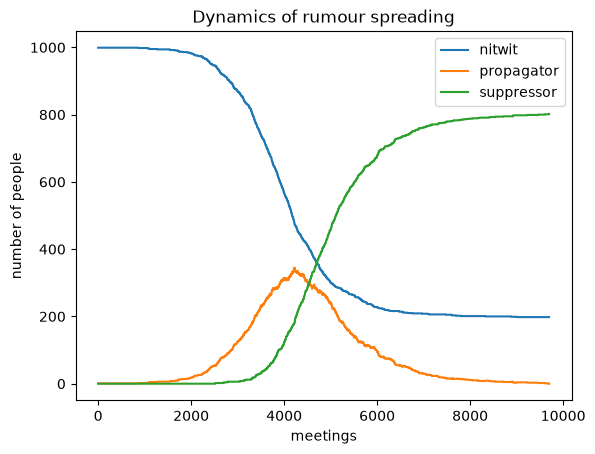

In [77]:
import csv

def simulate_daley_kendall_csv(N, filename):
    population = make_population(N)
    counts = count_roles(population)
    with open(filename, "w", newline="") as f:
        writer = csv.writer(f, delimiter=";", quoting=csv.QUOTE_NONNUMERIC)
        writer.writerow([NITWIT, PROPAGATOR, SUPPRESSOR])
        writer.writerow([counts[NITWIT], counts[PROPAGATOR], counts[SUPPRESSOR]])
        while counts[PROPAGATOR] > 0:
            i = random.randrange(N)
            j = random.randrange(N)
            if i == j:
                continue
            old_i, old_j = population[i], population[j]
            meet_daley_kendall(population, i, j)
            counts[old_i] = counts[old_i] - 1; counts[population[i]] = counts[population[i]] + 1
            counts[old_j] = counts[old_j] - 1; counts[population[j]] = counts[population[j]] + 1
            writer.writerow([counts[NITWIT], counts[PROPAGATOR], counts[SUPPRESSOR]])

def plot_csv(filename):
    import matplotlib.pyplot as plt
    columns = {NITWIT: [], PROPAGATOR: [], SUPPRESSOR: []}
    with open(filename) as f:
        reader = csv.reader(f, delimiter=";")
        header = next(reader)
        for row in reader:
            for name, value in zip(header, row):
                columns[name].append(int(value))
    for name in header:
        plt.plot(columns[name], label=name)
    plt.xlabel("meetings")
    plt.ylabel("number of people")
    plt.title("Dynamics of rumour spreading")
    plt.legend()
    plt.savefig("rumours.png")

# --- demo ---
random.seed(10)
simulate_daley_kendall_csv(1000, "output.csv")
with open("output.csv") as f:
    lines = f.readlines()
print("".join(lines[:4]), end="")
print("...")
print(lines[-1], end="")
print(len(lines) - 1, "rows written")
plot_csv("output.csv")

**Output (as printed on the sheet):**
```text
"nitwit";"propagator";"suppressor"
999;1;0
999;1;0
999;1;0
...
198;0;802
9698 rows written
```

The plot shows the number of propagators rising, peaking and dying out, while the suppressors take over and the nitwits level off at about 20 % of $N$.

**Typical pitfalls:**

* Opening the file *inside* the loop with mode `"w"` overwrites it in every step.
* On Windows, forgetting `newline=""` produces empty lines between the rows.

## Problem 65

Run each model 100 times for the population sizes $N = 100$ and $N = 1000$ (and, if your computer is fast enough, $N = 10000$) and compute the average fraction $\Theta$ of nitwits at the end. Write down your observations and hypotheses: Does $\Theta$ depend on $N$? Do both models give the same value? How much do individual runs vary? (Mathematicians have shown that for large $N$, $\Theta \approx 0.203$ for both models.)

**Idea:** For each model and each $N$, collect the 100 values of $\Theta$ in a list; print mean, minimum and maximum.

**Solution:**

In [78]:
random.seed(1)
models = [("Daley-Kendall", simulate_daley_kendall),
          ("Maki-Thompson", simulate_maki_thompson)]
for name, simulate in models:
    for N in [100, 1000]:
        thetas = []
        for run in range(100):
            counts = simulate(N)
            thetas.append(counts[NITWIT] / N)
        mean = sum(thetas) / len(thetas)
        print(f"{name:14} N = {N:5}  mean theta = {mean:.3f}"
              f"  min = {min(thetas):.3f}  max = {max(thetas):.3f}")

Daley-Kendall  N =   100  mean theta = 0.208  min = 0.070  max = 0.430
Daley-Kendall  N =  1000  mean theta = 0.206  min = 0.162  max = 0.250
Maki-Thompson  N =   100  mean theta = 0.208  min = 0.110  max = 0.360
Maki-Thompson  N =  1000  mean theta = 0.202  min = 0.143  max = 0.246


**Output (as printed on the sheet):**
```text
Daley-Kendall  N =   100  mean theta = 0.208  min = 0.070  max = 0.430
Daley-Kendall  N =  1000  mean theta = 0.206  min = 0.162  max = 0.250
Maki-Thompson  N =   100  mean theta = 0.208  min = 0.110  max = 0.360
Maki-Thompson  N =  1000  mean theta = 0.202  min = 0.143  max = 0.246
```

The averages are close to 0.2 for both models, and they approach 0.203 as $N$ grows. For small $N$ individual runs vary a lot (for $N = 100$ between roughly 7 % and 43 %), for $N = 1000$ much less: the larger the population, the more reliable a single run.

**Typical pitfalls:**

* Running only one simulation per setting and drawing conclusions from a single random outcome.